In [ ]:
!pip install -q datasets
from datasets import load_dataset
import pandas as pd

dataset = load_dataset("muzom/CIC-IDS2017")

print(dataset)
print(dataset["train"].column_names)
print("Rows:", dataset["train"].num_rows)


README.md:   0%|          | 0.00/771 [00:00<?, ?B/s]

Friday-WorkingHours-Afternoon-DDos.pcap_(…): reconstructing file:   0%|          |  0.00B / 77.1MB            

Friday-WorkingHours-Afternoon-DDos.pcap_(…): downloading bytes:           |  0.00B            

Friday-WorkingHours-Afternoon-PortScan.p(…): reconstructing file:   0%|          |  0.00B / 76.9MB            

Friday-WorkingHours-Afternoon-PortScan.p(…): downloading bytes:           |  0.00B            

...

Tuesday-WorkingHours.pcap_ISCX.csv: downloading bytes:           |  0.00B            

Wednesday-workingHours.pcap_ISCX.csv: reconstructing file:   0%|          |  0.00B /  225MB            

Wednesday-workingHours.pcap_ISCX.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2830743 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: [' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', 'FIN Flag Count', ' SYN Flag Count', ' RST Flag Coun

In [ ]:
# Day 1 — Initial Dataset Audit

import pandas as pd
import numpy as np

# Work directly with the Hugging Face dataset
train = dataset["train"]

print("Dataset type:", type(train))
print("Number of rows:", train.num_rows)
print("Number of columns:", len(train.column_names))

# Check target column
label_col = " Label" if " Label" in train.column_names else "Label"

print("\nTarget column:", label_col)

# Efficiently inspect labels without converting the full dataset
labels = train[label_col]

label_counts = pd.Series(labels).value_counts(dropna=False)

print("\n=== Label Distribution ===")
print(label_counts)

print("\n=== Number of Unique Labels ===")
print(label_counts.shape[0])

print("\n=== Labels ===")
print(label_counts.index.tolist())

Dataset type: <class 'datasets.arrow_dataset.Dataset'>
Number of rows: 2830743
Number of columns: 79

Target column:  Label

=== Label Distribution ===
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64

=== Number of Unique Labels ===
15

=== Labels ===
['BENIGN', 'DoS Hulk', 'PortScan', 'DDoS', 'DoS GoldenEye', 'FTP-Patator', 'SSH-Patator', 'DoS slowloris', 'DoS Slowhttptest', 'Bot', 'Web Attack � Brute Force', 'Web Attack � XSS', 'Infiltration', 'W

In [ ]:
# Day 1 — Data Quality Audit

import numpy as np
import pandas as pd

train = dataset["train"]

print("=== Dataset Overview ===")
print("Rows:", train.num_rows)
print("Columns:", len(train.column_names))

# --------------------------------------------------
# 1. Column names
# --------------------------------------------------

print("\n=== Column Name Check ===")

columns = train.column_names

leading_space_columns = [
    col for col in columns if col != col.strip()
]

print("Columns with leading/trailing spaces:", len(leading_space_columns))

print(leading_space_columns[:20])

# --------------------------------------------------
# 2. Dataset feature types
# --------------------------------------------------

print("\n=== Feature Types ===")

feature_types = train.features

for name, feature in list(feature_types.items())[:10]:
    print(name, "->", feature)

# --------------------------------------------------
# 3. Missing values
# --------------------------------------------------

print("\n=== Missing Value Audit ===")

# Check missing values in manageable batches
missing_counts = {}

for col in columns:
    values = train[col]
    missing_counts[col] = sum(
        value is None or (
            isinstance(value, float) and np.isnan(value)
        )
        for value in values
    )

missing_series = pd.Series(missing_counts).sort_values(ascending=False)

print(missing_series.head(15))

print("\nTotal columns containing missing values:",
      (missing_series > 0).sum())

# --------------------------------------------------
# 4. Infinite values
# --------------------------------------------------

print("\n=== Infinite Value Audit ===")

infinite_counts = {}

for col in columns:
    values = train[col]

    count = 0

    for value in values:
        if isinstance(value, (int, float, np.integer, np.floating)):
            if np.isinf(value):
                count += 1

    infinite_counts[col] = count

infinite_series = pd.Series(infinite_counts).sort_values(ascending=False)

print(infinite_series.head(15))

print("\nTotal columns containing infinite values:",
      (infinite_series > 0).sum())

# --------------------------------------------------
# 5. Constant columns
# --------------------------------------------------

print("\n=== Constant / Near-Constant Check ===")

constant_columns = []

for col in columns:
    unique_count = train[col].unique()

    if len(unique_count) <= 1:
        constant_columns.append(col)

print("Constant columns:", len(constant_columns))
print(constant_columns)

print("\n=== Audit Complete ===")

=== Dataset Overview ===
Rows: 2830743
Columns: 79

=== Column Name Check ===
Columns with leading/trailing spaces: 65
[' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max']

=== Feature Types ===
 Destination Port -> Value('int64')
 Flow Duration -> Value('int64')
 Total Fwd Packets -> Value('int64')
 Total Backward Packets -> Value('int64')
Total Length of Fwd Packets -> Value('int64')
 Total Length of Bwd Packets -> Value('int64')
 Fwd Packet Length Max -> Value('int64')
 Fwd Packet Length Min -> Value('int64')
 Fwd Packet Length Mean -> Value('float64')
 Fwd Packet Length Std -> Value('float64')

=== M

KeyboardInterrupt: 

In [ ]:
# FAST DATA QUALITY CHECK

import pandas as pd

train = dataset["train"]

print("Rows:", train.num_rows)
print("Columns:", len(train.column_names))

# Column-name issues
bad_columns = [c for c in train.column_names if c != c.strip()]

print("\nColumns with leading/trailing spaces:", len(bad_columns))
print(bad_columns)

# Dataset schema
print("\nFirst 10 feature types:")
for name, feature in list(train.features.items())[:10]:
    print(name, "->", feature)

# Small representative sample for quality inspection
sample = train.shuffle(seed=42).select(range(10000)).to_pandas()

print("\nSample shape:", sample.shape)

print("\nMissing values in 10,000-row sample:")
print(sample.isna().sum().sort_values(ascending=False).head(15))

print("\nInfinite values in numeric columns:")
numeric_sample = sample.select_dtypes(include="number")
print(numeric_sample.isin([float("inf"), float("-inf")]).sum()
      .sort_values(ascending=False).head(15))

print("\nConstant columns in sample:")
constant_cols = [
    col for col in sample.columns
    if sample[col].nunique(dropna=False) <= 1
]
print(constant_cols)

print("\nFAST AUDIT COMPLETE")

Rows: 2830743
Columns: 79

Columns with leading/trailing spaces: 65
[' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', ' SYN Flag Count', ' RST Flag Count', ' PSH Flag Count', ' ACK Flag Count', ' URG Flag Count', ' CWE Flag Count', ' ECE Flag Count', ' Down/Up Ratio', ' Average Packet Size', ' 

In [ ]:
# Day 1 — Feature Redundancy & Distribution Audit

import numpy as np
import pandas as pd

sample = train.shuffle(seed=42).select(range(10000)).to_pandas()

# Clean column names for analysis
sample.columns = sample.columns.str.strip()

# Separate target
X_sample = sample.drop(columns=["Label"])
y_sample = sample["Label"]

# Numeric columns
numeric_cols = X_sample.select_dtypes(include=np.number).columns

print("Numeric features:", len(numeric_cols))

# --------------------------------------------------
# 1. Constant features
# --------------------------------------------------

constant_cols = [
    col for col in numeric_cols
    if X_sample[col].nunique(dropna=False) <= 1
]

print("\n=== Constant Features ===")
print(constant_cols)

# --------------------------------------------------
# 2. Near-zero variance features
# --------------------------------------------------

variance = X_sample[numeric_cols].var(numeric_only=True)

print("\n=== Lowest Variance Features ===")
print(variance.sort_values().head(15))

# --------------------------------------------------
# 3. Highly correlated feature pairs
# --------------------------------------------------

corr = X_sample[numeric_cols].corr().abs()

upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

high_corr_pairs = (
    upper.stack()
    .sort_values(ascending=False)
)

high_corr_pairs = high_corr_pairs[
    high_corr_pairs >= 0.95
]

print("\n=== Highly Correlated Pairs (>= 0.95) ===")
print(high_corr_pairs.head(30))

# --------------------------------------------------
# 4. Basic numerical summary
# --------------------------------------------------

print("\n=== Numerical Summary ===")
print(
    X_sample[numeric_cols]
    .describe()
    .T[["mean", "std", "min", "max"]]
    .head(20)
)

print("\nFEATURE AUDIT COMPLETE")


Numeric features: 78

=== Constant Features ===
['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']

=== Lowest Variance Features ===
Bwd PSH Flags           0.000000
Fwd URG Flags           0.000000
Bwd URG Flags           0.000000
Fwd Avg Bulk Rate       0.000000
Bwd Avg Bulk Rate       0.000000
Bwd Avg Packets/Bulk    0.000000
Bwd Avg Bytes/Bulk      0.000000
CWE Flag Count          0.000000
Fwd Avg Bytes/Bulk      0.000000
Fwd Avg Packets/Bulk    0.000000
RST Flag Count          0.000400
ECE Flag Count          0.000400
FIN Flag Count          0.032288
SYN Flag Count          0.043616
Fwd PSH Flags           0.043616
dtype: float64

=== Highly Correlated Pairs (>= 0.95) ===
Fwd Packet Length Mean       Avg Fwd Segment Size           1.000000
Bwd Packet Length Mean       Avg Bwd Segment Size           1.000000
Fwd Header Length      

In [ ]:
# Day 1 — Final Structural Audit

import pandas as pd
import numpy as np

# Use the existing 10,000-row sample
sample = train.shuffle(seed=42).select(range(10000)).to_pandas()

# Clean column names
sample.columns = sample.columns.str.strip()

print("=== FINAL STRUCTURAL AUDIT ===")

# 1. Duplicate rows in sample
duplicate_rows = sample.duplicated().sum()

print("\nDuplicate rows in 10,000-row sample:", duplicate_rows)

# 2. Duplicate columns
duplicate_columns = []

for i in range(len(sample.columns)):
    for j in range(i + 1, len(sample.columns)):
        if sample.iloc[:, i].equals(sample.iloc[:, j]):
            duplicate_columns.append(
                (sample.columns[i], sample.columns[j])
            )

print("\nExact duplicate column pairs:")
print(duplicate_columns)

# 3. Invalid numeric values
numeric_cols = sample.select_dtypes(include=np.number).columns

inf_counts = np.isinf(sample[numeric_cols]).sum()
negative_counts = (sample[numeric_cols] < 0).sum()

print("\n=== Infinite Values ===")
print(inf_counts[inf_counts > 0])

print("\n=== Features Containing Negative Values ===")
print(negative_counts[negative_counts > 0].sort_values(ascending=False).head(20))

# 4. Missing values
missing = sample.isna().sum()
print("\n=== Missing Values ===")
print(missing[missing > 0])

print("\n=== FINAL AUDIT COMPLETE ===")

=== FINAL STRUCTURAL AUDIT ===

Duplicate rows in 10,000-row sample: 236

Exact duplicate column pairs:
[('Total Fwd Packets', 'Subflow Fwd Packets'), ('Total Backward Packets', 'Subflow Bwd Packets'), ('Total Length of Fwd Packets', 'Subflow Fwd Bytes'), ('Fwd Packet Length Mean', 'Avg Fwd Segment Size'), ('Bwd Packet Length Mean', 'Avg Bwd Segment Size'), ('Fwd PSH Flags', 'SYN Flag Count'), ('Bwd PSH Flags', 'Fwd URG Flags'), ('Bwd PSH Flags', 'Bwd URG Flags'), ('Bwd PSH Flags', 'CWE Flag Count'), ('Bwd PSH Flags', 'Fwd Avg Bytes/Bulk'), ('Bwd PSH Flags', 'Fwd Avg Packets/Bulk'), ('Bwd PSH Flags', 'Fwd Avg Bulk Rate'), ('Bwd PSH Flags', 'Bwd Avg Bytes/Bulk'), ('Bwd PSH Flags', 'Bwd Avg Packets/Bulk'), ('Bwd PSH Flags', 'Bwd Avg Bulk Rate'), ('Fwd URG Flags', 'Bwd URG Flags'), ('Fwd URG Flags', 'CWE Flag Count'), ('Fwd URG Flags', 'Fwd Avg Bytes/Bulk'), ('Fwd URG Flags', 'Fwd Avg Packets/Bulk'), ('Fwd URG Flags', 'Fwd Avg Bulk Rate'), ('Fwd URG Flags', 'Bwd Avg Bytes/Bulk'), ('Fwd UR

In [ ]:
# DAY 2 — CLEANING PIPELINE SETUP

import pandas as pd
import numpy as np

# Work with the Hugging Face dataset
train = dataset["train"]

# Create a manageable working sample for pipeline validation
working_sample = train.shuffle(seed=42).select(range(100000)).to_pandas()

print("Original sample shape:", working_sample.shape)

# --------------------------------------------------
# 1. Normalize column names
# --------------------------------------------------

working_sample.columns = working_sample.columns.str.strip()

print("\nColumn names normalized.")

# --------------------------------------------------
# 2. Separate target
# --------------------------------------------------

TARGET = "Label"

X = working_sample.drop(columns=[TARGET])
y = working_sample[TARGET]

# --------------------------------------------------
# 3. Remove constant features
# --------------------------------------------------

constant_features = [
    col for col in X.columns
    if X[col].nunique(dropna=False) <= 1
]

X = X.drop(columns=constant_features)

print("\nConstant features removed:", len(constant_features))
print(constant_features)

# --------------------------------------------------
# 4. Replace infinite values
# --------------------------------------------------

inf_before = np.isinf(X.select_dtypes(include=np.number)).sum().sum()

X = X.replace([np.inf, -np.inf], np.nan)

print("\nInfinite values converted to NaN:", inf_before)

# --------------------------------------------------
# 5. Missing-value report
# --------------------------------------------------

missing = X.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print("\nMissing values after infinity conversion:")
print(missing)

# --------------------------------------------------
# 6. Recombine
# --------------------------------------------------

clean_sample = X.copy()
clean_sample[TARGET] = y.values

print("\nFinal working sample shape:", clean_sample.shape)

print("\nFinal class distribution:")
print(clean_sample[TARGET].value_counts())

print("\nDAY 2 CLEANING SETUP COMPLETE")

Original sample shape: (100000, 79)

Column names normalized.

Constant features removed: 8
['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']

Infinite values converted to NaN: 160

Missing values after infinity conversion:
Flow Bytes/s      103
Flow Packets/s    103
dtype: int64

Final working sample shape: (100000, 71)

Final class distribution:
Label
BENIGN                        80356
DoS Hulk                       8097
PortScan                       5583
DDoS                           4628
DoS GoldenEye                   324
FTP-Patator                     269
SSH-Patator                     216
DoS Slowhttptest                197
DoS slowloris                   188
Bot                              59
Web Attack � Brute Force         52
Web Attack � XSS                 25
Infiltration                      3
Web Attack � Sql Injection        2
Heartbleed           

In [ ]:
# DAY 2 — LEAKAGE-SAFE TRAIN/TEST SPLIT

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Use the validated 100k cleaned sample
data = clean_sample.copy()

# --------------------------------------------------
# 1. Separate features and target
# --------------------------------------------------

X = data.drop(columns=["Label"])
y = data["Label"]

# --------------------------------------------------
# 2. Stratified split
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("=== TRAIN / TEST SPLIT ===")

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

# --------------------------------------------------
# 3. Verify no target leakage
# --------------------------------------------------

print("\nTarget column present in X_train:",
      "Label" in X_train.columns)

print("Target column present in X_test:",
      "Label" in X_test.columns)

print("\nLEAKAGE-SAFE SPLIT COMPLETE")

ValueError: The least populated class in y has only 1 member, which is too few. The minimum number of groups for any class cannot be less than 2.

In [ ]:
# DAY 2 — CLASS-AWARE MODELING SAMPLE

from collections import Counter
import pandas as pd
import numpy as np

train = dataset["train"]

# --------------------------------------------------
# 1. Create a reproducible random sample
# --------------------------------------------------

SAMPLE_SIZE = 500_000

sample = train.shuffle(seed=42).select(
    range(min(SAMPLE_SIZE, train.num_rows))
).to_pandas()

# Normalize column names
sample.columns = sample.columns.str.strip()

print("Initial modeling sample:", sample.shape)

# --------------------------------------------------
# 2. Clean infinite values
# --------------------------------------------------

sample = sample.replace([np.inf, -np.inf], np.nan)

# --------------------------------------------------
# 3. Remove constant columns based on this sample
# --------------------------------------------------

TARGET = "Label"

X_temp = sample.drop(columns=[TARGET])

constant_features = [
    col for col in X_temp.columns
    if X_temp[col].nunique(dropna=False) <= 1
]

sample = sample.drop(columns=constant_features)

print("Constant features removed:", len(constant_features))

# --------------------------------------------------
# 4. Show class distribution
# --------------------------------------------------

class_counts = sample[TARGET].value_counts()

print("\n=== MODELING SAMPLE CLASS DISTRIBUTION ===")
print(class_counts)

print("\nNumber of classes:", class_counts.shape[0])

print("\nRare classes (< 10 samples):")
print(class_counts[class_counts < 10])

print("\n=== MODELING SAMPLE READY FOR NEXT STEP ===")

In [ ]:
# DAY 2 — LEAKAGE-SAFE TRAIN/TEST SPLIT

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Use the validated 100k cleaned sample
data = clean_sample.copy()

# --------------------------------------------------
# 1. Separate features and target
# --------------------------------------------------

X = data.drop(columns=["Label"])
y = data["Label"]

# --------------------------------------------------
# 2. Stratified split
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("=== TRAIN / TEST SPLIT ===")

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

# --------------------------------------------------
# 3. Verify no target leakage
# --------------------------------------------------

print("\nTarget column present in X_train:",
      "Label" in X_train.columns)

print("Target column present in X_test:",
      "Label" in X_test.columns)

print("\nLEAKAGE-SAFE SPLIT COMPLETE")

ValueError: The least populated class in y has only 1 member, which is too few. The minimum number of groups for any class cannot be less than 2.

print("NEW CELL TEST — no train_test_split")
print("Current dataset rows:", dataset["train"].num_rows)

In [ ]:
# DAY 2 — CLASS-AWARE MODELING SAMPLE

from collections import Counter
import pandas as pd
import numpy as np

train = dataset["train"]

# --------------------------------------------------
# 1. Create a reproducible random sample
# --------------------------------------------------

SAMPLE_SIZE = 500_000

sample = train.shuffle(seed=42).select(
    range(min(SAMPLE_SIZE, train.num_rows))
).to_pandas()

# Normalize column names
sample.columns = sample.columns.str.strip()

print("Initial modeling sample:", sample.shape)

# --------------------------------------------------
# 2. Clean infinite values
# --------------------------------------------------

sample = sample.replace([np.inf, -np.inf], np.nan)

# --------------------------------------------------
# 3. Remove constant columns based on this sample
# --------------------------------------------------

TARGET = "Label"

X_temp = sample.drop(columns=[TARGET])

constant_features = [
    col for col in X_temp.columns
    if X_temp[col].nunique(dropna=False) <= 1
]

sample = sample.drop(columns=constant_features)

print("Constant features removed:", len(constant_features))

# --------------------------------------------------
# 4. Show class distribution
# --------------------------------------------------

class_counts = sample[TARGET].value_counts()

print("\n=== MODELING SAMPLE CLASS DISTRIBUTION ===")
print(class_counts)

print("\nNumber of classes:", class_counts.shape[0])

print("\nRare classes (< 10 samples):")
print(class_counts[class_counts < 10])

print("\n=== MODELING SAMPLE READY FOR NEXT STEP ===")

NameError: name 'dataset' is not defined

In [ ]:
print("NEW CELL TEST — no train_test_split")
print("Current dataset rows:", dataset["train"].num_rows)

NEW CELL TEST — no train_test_split


NameError: name 'dataset' is not defined

In [ ]:
print("NEW CELL TEST — no train_test_split")
print("Current dataset rows:", dataset["train"].num_rows)

NEW CELL TEST — no train_test_split


NameError: name 'dataset' is not defined

print("NEW CELL TEST — no train_test_split")
print("Current dataset rows:", dataset["train"].num_rows)


In [ ]:
print("TEST OK")
print("Rows:", dataset["train"].num_rows)

TEST OK


NameError: name 'dataset' is not defined

In [ ]:
from datasets import load_dataset

dataset = load_dataset("muzom/CIC-IDS2017")

print("Dataset loaded successfully!")
print(dataset)
print("Rows:", dataset["train"].num_rows)

Dataset loaded successfully!
DatasetDict({
    train: Dataset({
        features: [' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', 'FIN Flag Count', ' SYN

In [ ]:
# ============================================================
# STEP 1 — FULL DATASET CLASS AUDIT
# ============================================================

from collections import Counter

train = dataset["train"]

# Label column
label_col = " Label"

# Count every class from the full dataset
label_counts = Counter(train[label_col])

print("=" * 60)
print("FULL DATASET CLASS DISTRIBUTION")
print("=" * 60)

for label, count in label_counts.most_common():
    percentage = (count / len(train)) * 100
    print(f"{label:35s} {count:10,d}  ({percentage:6.2f}%)")

print("=" * 60)
print(f"Total rows: {len(train):,}")
print(f"Total classes: {len(label_counts)}")
print("=" * 60)

FULL DATASET CLASS DISTRIBUTION
BENIGN                               2,273,097  ( 80.30%)
DoS Hulk                               231,073  (  8.16%)
PortScan                               158,930  (  5.61%)
DDoS                                   128,027  (  4.52%)
DoS GoldenEye                           10,293  (  0.36%)
FTP-Patator                              7,938  (  0.28%)
SSH-Patator                              5,897  (  0.21%)
DoS slowloris                            5,796  (  0.20%)
DoS Slowhttptest                         5,499  (  0.19%)
Bot                                      1,966  (  0.07%)
Web Attack � Brute Force                 1,507  (  0.05%)
Web Attack � XSS                           652  (  0.02%)
Infiltration                                36  (  0.00%)
Web Attack � Sql Injection                  21  (  0.00%)
Heartbleed                                  11  (  0.00%)
Total rows: 2,830,743
Total classes: 15


In [ ]:
# ============================================================
# STEP 2 — BUILD RESEARCH-GRADE MODELING SAMPLE
# ============================================================

from collections import defaultdict
import random

train = dataset["train"]
label_col = " Label"

# Maximum number of rows per class for the primary multiclass dataset
MAX_PER_CLASS = 50_000

# Classes with enough observations for reliable stratified evaluation
PRIMARY_MIN_COUNT = 50

# Get exact class counts
label_counts = Counter(train[label_col])

# Primary classes
primary_classes = [
    label for label, count in label_counts.items()
    if count >= PRIMARY_MIN_COUNT
]

# Rare classes
rare_classes = [
    label for label, count in label_counts.items()
    if count < PRIMARY_MIN_COUNT
]

print("=" * 60)
print("PRIMARY MODELING CLASSES")
print("=" * 60)

for label in sorted(primary_classes):
    print(f"{label:35s} {label_counts[label]:10,d}")

print("\n" + "=" * 60)
print("RARE CLASSES — SEPARATE ANALYSIS")
print("=" * 60)

for label in sorted(rare_classes):
    print(f"{label:35s} {label_counts[label]:10,d}")

print("\n" + "=" * 60)
print(f"Primary classes: {len(primary_classes)}")
print(f"Rare classes: {len(rare_classes)}")
print("=" * 60)

# ------------------------------------------------------------
# Collect indices class-by-class
# ------------------------------------------------------------

class_indices = defaultdict(list)

for i, label in enumerate(train[label_col]):
    if label in primary_classes:
        class_indices[label].append(i)

# ------------------------------------------------------------
# Sample up to MAX_PER_CLASS from each primary class
# ------------------------------------------------------------

random.seed(42)

selected_indices = []

for label in primary_classes:
    indices = class_indices[label]

    if len(indices) > MAX_PER_CLASS:
        indices = random.sample(indices, MAX_PER_CLASS)

    selected_indices.extend(indices)

# Shuffle final indices
random.shuffle(selected_indices)

print("\nSelected rows:", f"{len(selected_indices):,}")

# ------------------------------------------------------------
# Create modeling dataset
# ------------------------------------------------------------

model_dataset = train.select(selected_indices)

print("\nModeling dataset created successfully!")
print(model_dataset)

PRIMARY MODELING CLASSES
BENIGN                               2,273,097
Bot                                      1,966
DDoS                                   128,027
DoS GoldenEye                           10,293
DoS Hulk                               231,073
DoS Slowhttptest                         5,499
DoS slowloris                            5,796
FTP-Patator                              7,938
PortScan                               158,930
SSH-Patator                              5,897
Web Attack � Brute Force                 1,507
Web Attack � XSS                           652

RARE CLASSES — SEPARATE ANALYSIS
Heartbleed                                  11
Infiltration                                36
Web Attack � Sql Injection                  21

Primary classes: 12
Rare classes: 3

Selected rows: 239,548

Modeling dataset created successfully!
Dataset({
    features: [' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd P

In [ ]:
# ============================================================
# STEP 3 — DATA CLEANING & QUALITY VALIDATION
# ============================================================

import pandas as pd
import numpy as np

print("=" * 70)
print("CONVERTING MODELING DATASET TO PANDAS")
print("=" * 70)

# Convert the selected Hugging Face dataset to pandas
df = model_dataset.to_pandas()

print("Initial shape:", df.shape)

# ------------------------------------------------------------
# 1. CLEAN COLUMN NAMES
# ------------------------------------------------------------

df.columns = df.columns.str.strip()

print("\nColumn names cleaned.")

# ------------------------------------------------------------
# 2. VERIFY TARGET COLUMN
# ------------------------------------------------------------

TARGET = "Label"

if TARGET not in df.columns:
    raise ValueError("Target column 'Label' was not found.")

print("Target column:", TARGET)

# ------------------------------------------------------------
# 3. REMOVE EXACT DUPLICATE ROWS
# ------------------------------------------------------------

duplicate_rows = df.duplicated().sum()

print("\nDuplicate rows found:", f"{duplicate_rows:,}")

if duplicate_rows > 0:
    df = df.drop_duplicates().reset_index(drop=True)

print("Shape after duplicate removal:", df.shape)

# ------------------------------------------------------------
# 4. CONVERT NUMERIC FEATURES
# ------------------------------------------------------------

feature_columns = [col for col in df.columns if col != TARGET]

for col in feature_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# ------------------------------------------------------------
# 5. REPLACE INF / -INF WITH NaN
# ------------------------------------------------------------

inf_count = np.isinf(df[feature_columns].to_numpy()).sum()

print("\nInfinite values found:", f"{inf_count:,}")

df[feature_columns] = df[feature_columns].replace(
    [np.inf, -np.inf],
    np.nan
)

# ------------------------------------------------------------
# 6. MISSING VALUE AUDIT
# ------------------------------------------------------------

missing = df[feature_columns].isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print("\n" + "=" * 70)
print("MISSING VALUES")
print("=" * 70)

if len(missing) == 0:
    print("No missing values found.")
else:
    for col, count in missing.items():
        percentage = (count / len(df)) * 100
        print(f"{col:35s} {count:10,d} ({percentage:.4f}%)")

# ------------------------------------------------------------
# 7. CONSTANT FEATURE DETECTION
# ------------------------------------------------------------

constant_features = [
    col for col in feature_columns
    if df[col].nunique(dropna=False) <= 1
]

print("\n" + "=" * 70)
print("CONSTANT FEATURES")
print("=" * 70)

if constant_features:
    for col in constant_features:
        print("-", col)
else:
    print("No constant features found.")

# Remove constant features
if constant_features:
    df = df.drop(columns=constant_features)

# Update feature list
feature_columns = [col for col in df.columns if col != TARGET]

# ------------------------------------------------------------
# 8. TARGET DISTRIBUTION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TARGET DISTRIBUTION AFTER CLEANING")
print("=" * 70)

target_counts = df[TARGET].value_counts()

for label, count in target_counts.items():
    percentage = (count / len(df)) * 100
    print(f"{label:35s} {count:10,d} ({percentage:6.2f}%)")

# ------------------------------------------------------------
# 9. DATA TYPES
# ------------------------------------------------------------

non_numeric = df[feature_columns].select_dtypes(
    exclude=[np.number]
).columns.tolist()

print("\nNon-numeric feature columns:", len(non_numeric))

if non_numeric:
    print(non_numeric)

# ------------------------------------------------------------
# 10. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL CLEANING SUMMARY")
print("=" * 70)

print("Final shape:", df.shape)
print("Features:", len(feature_columns))
print("Target:", TARGET)
print("Duplicate rows removed:", f"{duplicate_rows:,}")
print("Infinite values detected:", f"{inf_count:,}")
print("Constant features removed:", len(constant_features))
print("Missing-value columns:", len(missing))
print("=" * 70)

print("\nDATA CLEANING AUDIT COMPLETE.")

CONVERTING MODELING DATASET TO PANDAS
Initial shape: (239548, 79)

Column names cleaned.
Target column: Label

Duplicate rows found: 28,812
Shape after duplicate removal: (210736, 79)

Infinite values found: 155

MISSING VALUES
Flow Bytes/s                                84 (0.0399%)
Flow Packets/s                              84 (0.0399%)

CONSTANT FEATURES
- Bwd PSH Flags
- Bwd URG Flags
- Fwd Avg Bytes/Bulk
- Fwd Avg Packets/Bulk
- Fwd Avg Bulk Rate
- Bwd Avg Bytes/Bulk
- Bwd Avg Packets/Bulk
- Bwd Avg Bulk Rate

TARGET DISTRIBUTION AFTER CLEANING
DDoS                                    49,999 ( 23.73%)
BENIGN                                  49,232 ( 23.36%)
PortScan                                39,388 ( 18.69%)
DoS Hulk                                37,991 ( 18.03%)
DoS GoldenEye                           10,286 (  4.88%)
FTP-Patator                              5,933 (  2.82%)
DoS slowloris                            5,385 (  2.56%)
DoS Slowhttptest                         5,2

In [ ]:
# ============================================================
# STEP 4 — LEAKAGE-SAFE TRAIN / TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns=[TARGET])
y = df[TARGET]

print("=" * 70)
print("TRAIN / TEST SPLIT")
print("=" * 70)

print("Total samples:", f"{len(df):,}")
print("Total features:", X.shape[1])
print("Total classes:", y.nunique())

# 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTrain shape:", X_train.shape)
print("Test shape :", X_test.shape)

print("\n" + "=" * 70)
print("TRAIN CLASS DISTRIBUTION")
print("=" * 70)

train_counts = y_train.value_counts()

for label, count in train_counts.items():
    print(
        f"{label:35s} "
        f"{count:10,d} "
        f"({count / len(y_train) * 100:6.2f}%)"
    )

print("\n" + "=" * 70)
print("TEST CLASS DISTRIBUTION")
print("=" * 70)

test_counts = y_test.value_counts()

for label, count in test_counts.items():
    print(
        f"{label:35s} "
        f"{count:10,d} "
        f"({count / len(y_test) * 100:6.2f}%)"
    )

print("\n" + "=" * 70)
print("CHECK")
print("=" * 70)

print("Training missing values:")
print(X_train.isna().sum().sum())

print("Testing missing values:")
print(X_test.isna().sum().sum())

print("\nLeakage-safe split completed.")

TRAIN / TEST SPLIT
Total samples: 210,736
Total features: 70
Total classes: 12

Train shape: (168588, 70)
Test shape : (42148, 70)

TRAIN CLASS DISTRIBUTION
DDoS                                    39,999 ( 23.73%)
BENIGN                                  39,386 ( 23.36%)
PortScan                                31,510 ( 18.69%)
DoS Hulk                                30,393 ( 18.03%)
DoS GoldenEye                            8,229 (  4.88%)
FTP-Patator                              4,746 (  2.82%)
DoS slowloris                            4,308 (  2.56%)
DoS Slowhttptest                         4,182 (  2.48%)
SSH-Patator                              2,575 (  1.53%)
Bot                                      1,562 (  0.93%)
Web Attack � Brute Force                 1,176 (  0.70%)
Web Attack � XSS                           522 (  0.31%)

TEST CLASS DISTRIBUTION
DDoS                                    10,000 ( 23.73%)
BENIGN                                   9,846 ( 23.36%)
PortScan            

In [ ]:
# STEP 5 — MISSING VALUE IMPUTATION

from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Train missing:", X_train_imputed.isna().sum().sum())
print("Test missing :", X_test_imputed.isna().sum().sum())
print("Train shape  :", X_train_imputed.shape)
print("Test shape   :", X_test_imputed.shape)

Train missing: 0
Test missing : 0
Train shape  : (168588, 70)
Test shape   : (42148, 70)


In [ ]:
# STEP 6 — FEATURE SCALING

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Train scaled shape:", X_train_scaled.shape)
print("Test scaled shape :", X_test_scaled.shape)
print("Scaling complete.")

Train scaled shape: (168588, 70)
Test scaled shape : (42148, 70)
Scaling complete.


In [ ]:
# STEP 7 — BASELINE MODEL: LOGISTIC REGRESSION

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42,
    n_jobs=-1
)

lr_model.fit(X_train_scaled, y_train)

y_pred_lr = lr_model.predict(X_test_scaled)

print("Logistic Regression Accuracy:",
      round(accuracy_score(y_test, y_pred_lr), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Logistic Regression Accuracy: 0.9714

Classification Report:
                          precision    recall  f1-score   support

                  BENIGN       0.95      0.94      0.95      9846
                     Bot       0.90      0.35      0.51       391
                    DDoS       0.99      1.00      0.99     10000
           DoS GoldenEye       0.99      0.98      0.98      2057
                DoS Hulk       0.98      1.00      0.99      7598
        DoS Slowhttptest       0.97      0.97      0.97      1046
           DoS slowloris       0.99      0.92      0.95      1077
             FTP-Patator       0.96      0.99      0.98      1187
                PortScan       0.97      1.00      0.99      7878
             SSH-Patator       0.99      0.92      0.96       644
Web Attack � Brute Force       0.61      0.91      0.73       294
        Web Attack � XSS       1.00      0.01      0.02       130

                accuracy                           0.97     42148
             

In [ ]:
# STEP 8 — RANDOM FOREST

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_model.fit(X_train_imputed, y_train)

y_pred_rf = rf_model.predict(X_test_imputed)

print("Random Forest Accuracy:",
      round(accuracy_score(y_test, y_pred_rf), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 0.9952

Classification Report:
                          precision    recall  f1-score   support

                  BENIGN       1.00      1.00      1.00      9846
                     Bot       0.98      0.99      0.98       391
                    DDoS       1.00      1.00      1.00     10000
           DoS GoldenEye       1.00      1.00      1.00      2057
                DoS Hulk       1.00      1.00      1.00      7598
        DoS Slowhttptest       1.00      0.99      1.00      1046
           DoS slowloris       1.00      1.00      1.00      1077
             FTP-Patator       1.00      1.00      1.00      1187
                PortScan       1.00      1.00      1.00      7878
             SSH-Patator       1.00      1.00      1.00       644
Web Attack � Brute Force       0.74      0.82      0.78       294
        Web Attack � XSS       0.45      0.32      0.38       130

                accuracy                           1.00     42148
               macr

In [ ]:
# STEP 9 — XGBOOST

from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=8,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softmax",
    num_class=len(label_encoder.classes_),
    eval_metric="mlogloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train_imputed,
    y_train_encoded
)

y_pred_xgb_encoded = xgb_model.predict(X_test_imputed)
y_pred_xgb = label_encoder.inverse_transform(y_pred_xgb_encoded)

print("XGBoost Accuracy:",
      round(accuracy_score(y_test, y_pred_xgb), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

XGBoost Accuracy: 0.9957

Classification Report:
                          precision    recall  f1-score   support

                  BENIGN       1.00      1.00      1.00      9846
                     Bot       0.99      0.99      0.99       391
                    DDoS       1.00      1.00      1.00     10000
           DoS GoldenEye       1.00      1.00      1.00      2057
                DoS Hulk       1.00      1.00      1.00      7598
        DoS Slowhttptest       1.00      0.99      1.00      1046
           DoS slowloris       1.00      1.00      1.00      1077
             FTP-Patator       1.00      1.00      1.00      1187
                PortScan       1.00      1.00      1.00      7878
             SSH-Patator       1.00      1.00      1.00       644
Web Attack � Brute Force       0.73      0.82      0.77       294
        Web Attack � XSS       0.44      0.32      0.37       130

                accuracy                           1.00     42148
               macro avg 

In [ ]:
# STEP 10 — MODEL COMPARISON

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_xgb)
    ],
    "Macro Precision": [
        precision_score(y_test, y_pred_lr, average="macro", zero_division=0),
        precision_score(y_test, y_pred_rf, average="macro", zero_division=0),
        precision_score(y_test, y_pred_xgb, average="macro", zero_division=0)
    ],
    "Macro Recall": [
        recall_score(y_test, y_pred_lr, average="macro", zero_division=0),
        recall_score(y_test, y_pred_rf, average="macro", zero_division=0),
        recall_score(y_test, y_pred_xgb, average="macro", zero_division=0)
    ],
    "Macro F1": [
        f1_score(y_test, y_pred_lr, average="macro"),
        f1_score(y_test, y_pred_rf, average="macro"),
        f1_score(y_test, y_pred_xgb, average="macro")
    ]
})

results = results.sort_values("Macro F1", ascending=False)

print(results.to_string(index=False))

print("\nBest model by Macro F1:",
      results.iloc[0]["Model"])

              Model  Accuracy  Macro Precision  Macro Recall  Macro F1
      Random Forest  0.995231         0.929437      0.926376  0.926883
            XGBoost  0.995729         0.928637      0.926491  0.926643
Logistic Regression  0.971434         0.942163      0.833625  0.834681

Best model by Macro F1: Random Forest


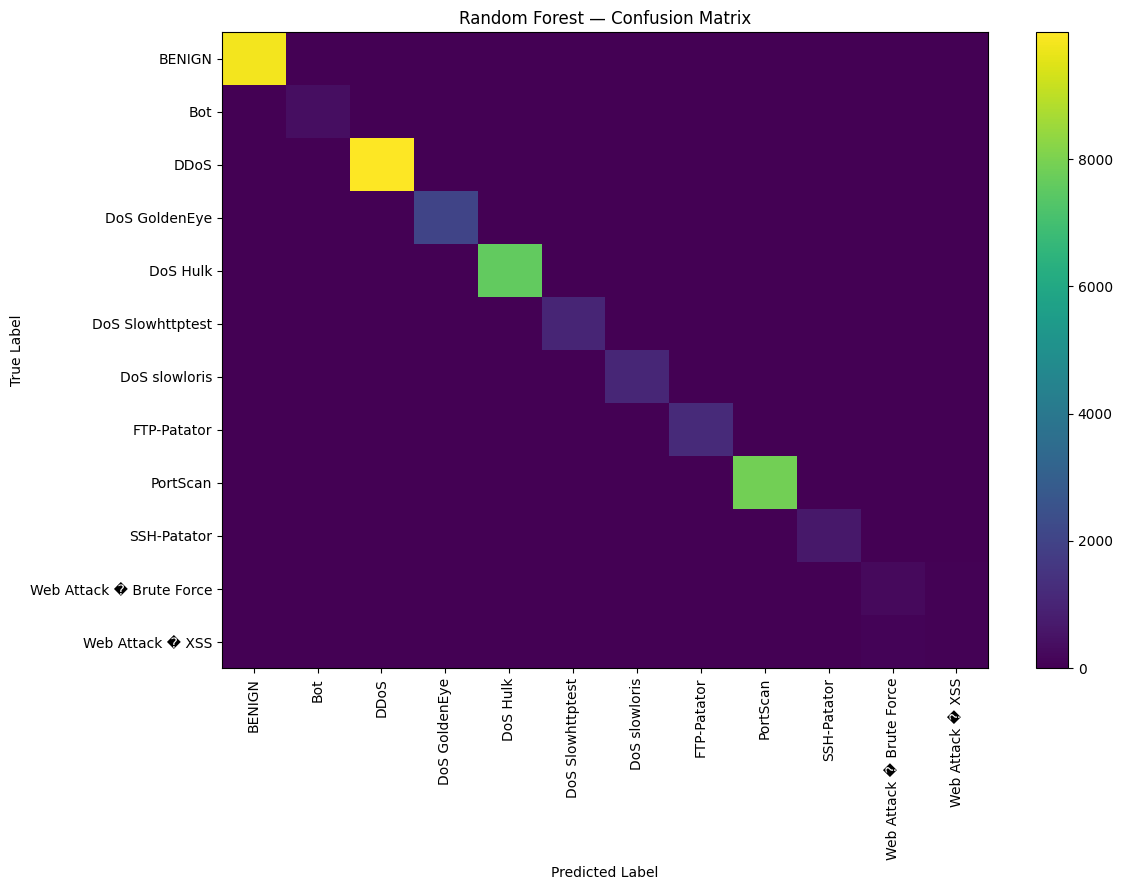

In [ ]:
# STEP 11 — CONFUSION MATRIX + PER-CLASS PERFORMANCE

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_rf, labels=label_encoder.classes_)

plt.figure(figsize=(12, 9))
plt.imshow(cm, aspect="auto")
plt.title("Random Forest — Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(
    range(len(label_encoder.classes_)),
    label_encoder.classes_,
    rotation=90
)
plt.yticks(
    range(len(label_encoder.classes_)),
    label_encoder.classes_
)
plt.colorbar()
plt.tight_layout()
plt.show()

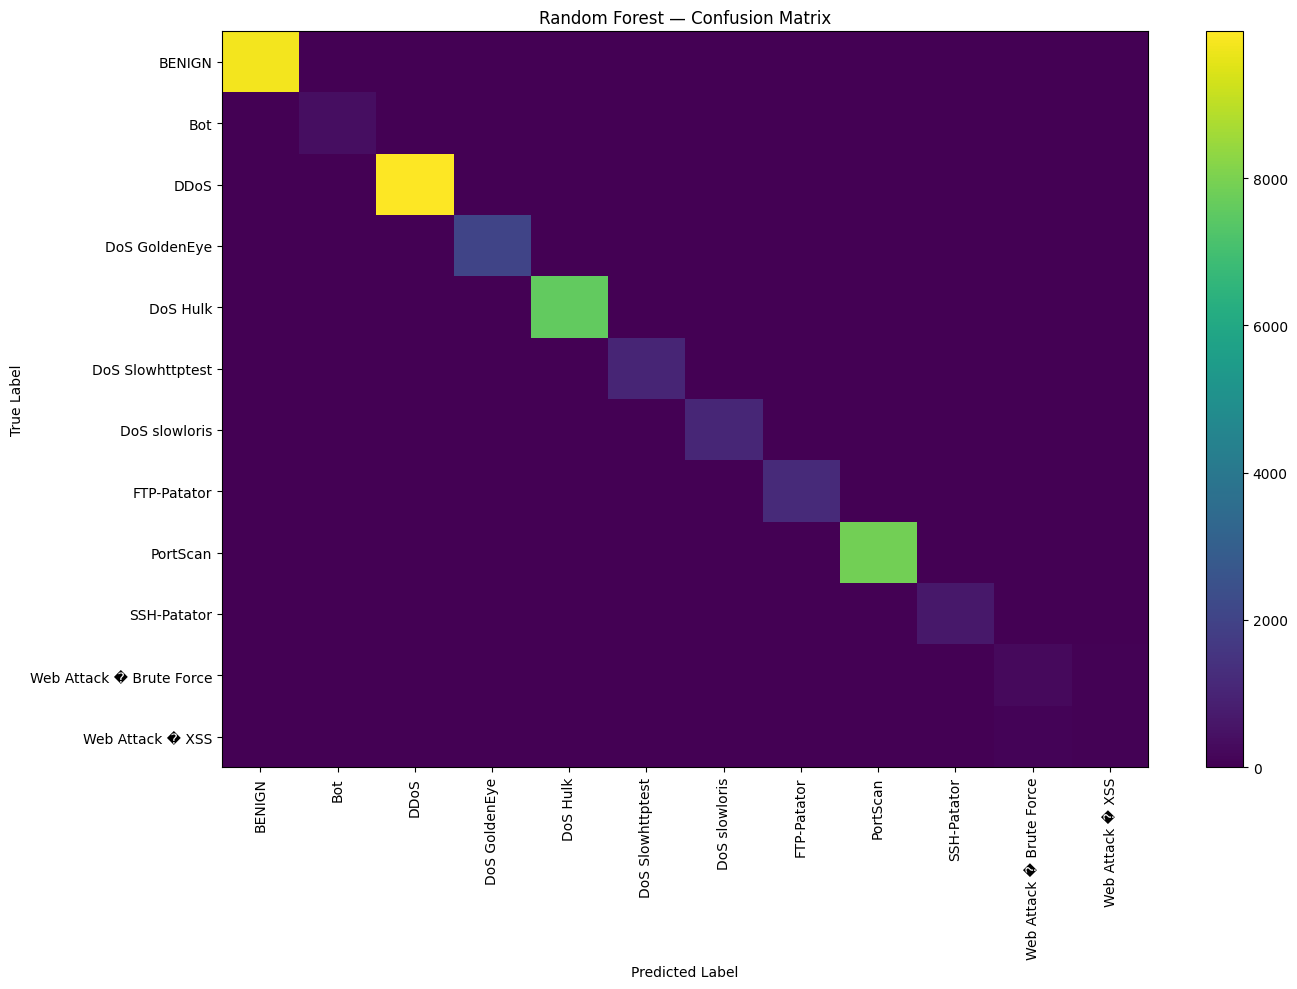

In [ ]:
# STEP 11 — CONFUSION MATRIX

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_rf, labels=label_encoder.classes_)

plt.figure(figsize=(14, 10))
plt.imshow(cm, aspect="auto")
plt.title("Random Forest — Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks(
    range(len(label_encoder.classes_)),
    label_encoder.classes_,
    rotation=90
)

plt.yticks(
    range(len(label_encoder.classes_)),
    label_encoder.classes_
)

plt.colorbar()
plt.tight_layout()
plt.show()

                Feature  Importance
       Destination Port    0.070835
Init_Win_bytes_backward    0.050149
          Bwd Packets/s    0.033387
  Fwd Packet Length Max    0.029279
      Bwd Header Length    0.026665
          Flow IAT Mean    0.025531
           Flow IAT Std    0.024603
          Flow Duration    0.024454
 Init_Win_bytes_forward    0.023757
         Flow Packets/s    0.023549
           Flow IAT Max    0.023417
     Packet Length Mean    0.021920
   min_seg_size_forward    0.021781
           Fwd IAT Mean    0.021717
    Average Packet Size    0.020676
            Fwd IAT Max    0.020386
    Fwd Header Length.1    0.020367
          Fwd Packets/s    0.019414
   Avg Bwd Segment Size    0.019126
 Bwd Packet Length Mean    0.018907


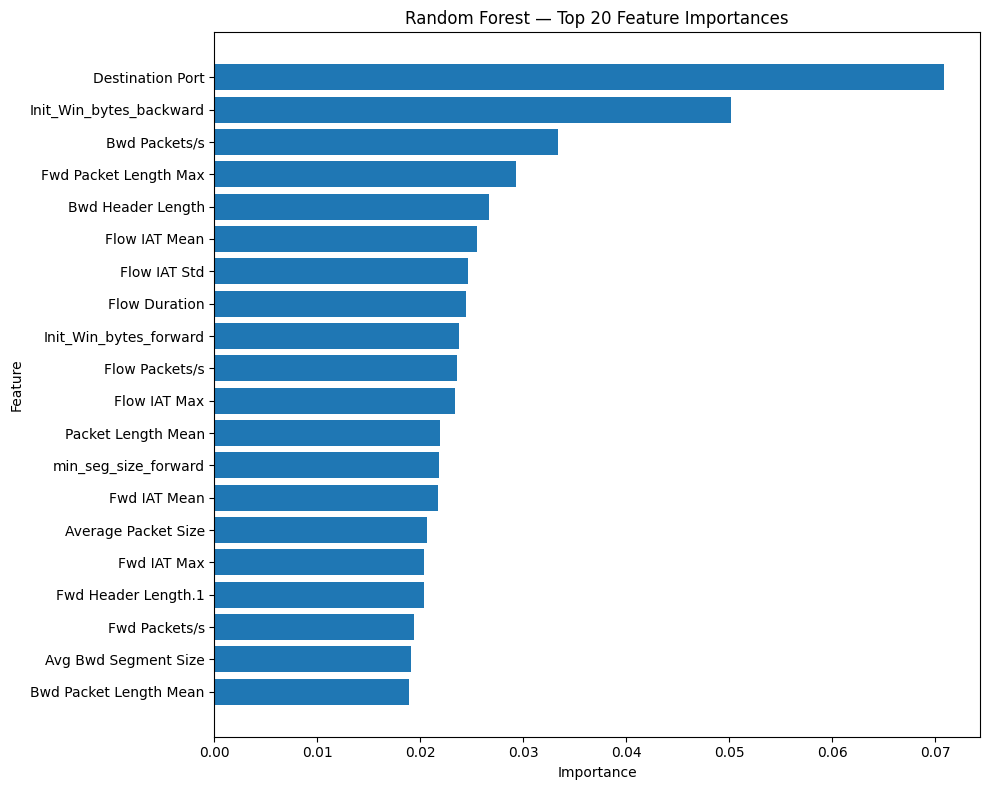

In [ ]:
# STEP 12 — RANDOM FOREST FEATURE IMPORTANCE

import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.DataFrame({
    "Feature": X_train_imputed.columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

print(feature_importance.head(20).to_string(index=False))

plt.figure(figsize=(10, 8))
top20 = feature_importance.head(20).sort_values("Importance")

plt.barh(top20["Feature"], top20["Importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest — Top 20 Feature Importances")
plt.tight_layout()
plt.show()


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Predictions on test set
y_pred = model.predict(X_test)

# Basic evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print("Model Evaluation")
print("=" * 40)
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

print("\nClassification Report")
print("=" * 40)
print(classification_report(y_test, y_pred, zero_division=0))

NameError: name 'model' is not defined

In [ ]:
# Show variables currently available in the notebook
%whos

Variable                 Type                      Data/Info
------------------------------------------------------------
Counter                  type                      <class 'collections.Counter'>
LabelEncoder             type                      <class 'sklearn.preproces<...>ing._label.LabelEncoder'>
LogisticRegression       type                      <class 'sklearn.linear_mo<...>stic.LogisticRegression'>
MAX_PER_CLASS            int                       50000
PRIMARY_MIN_COUNT        int                       50
RandomForestClassifier   ABCMeta                   <class 'sklearn.ensemble.<...>.RandomForestClassifier'>
SimpleImputer            type                      <class 'sklearn.impute._base.SimpleImputer'>
StandardScaler           type                      <class 'sklearn.preproces<...>ng._data.StandardScaler'>
TARGET                   str                       Label
X                        DataFrame                         Destination Port <...>210736 rows x 70 columns

In [ ]:
# Model Evaluation Summary

evaluation_results = []

models = {
    "Logistic Regression": y_pred_lr,
    "Random Forest": y_pred_rf,
    "XGBoost": y_pred_xgb
}

for model_name, predictions in models.items():
    evaluation_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, predictions, average="weighted", zero_division=0),
        "F1-Score": f1_score(y_test, predictions, average="weighted", zero_division=0)
    })

evaluation_df = pd.DataFrame(evaluation_results)

print("Model Evaluation Results")
print("=" * 70)
display(evaluation_df.round(4))

Model Evaluation Results


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.9714,0.9723,0.9714,0.9689
1,Random Forest,0.9952,0.9950,0.9952,0.9951
2,XGBoost,0.9957,0.9955,0.9957,0.9956


In [ ]:
from sklearn.metrics import classification_report

# XGBoost Per-Class Performance
xgb_report = classification_report(
    y_test,
    y_pred_xgb,
    target_names=label_encoder.classes_,
    digits=4,
    zero_division=0
)

print("XGBoost - Per-Class Classification Report")
print("=" * 80)
print(xgb_report)

XGBoost - Per-Class Classification Report
                          precision    recall  f1-score   support

                  BENIGN     0.9988    0.9987    0.9987      9846
                     Bot     0.9873    0.9923    0.9898       391
                    DDoS     0.9999    0.9999    0.9999     10000
           DoS GoldenEye     0.9995    0.9990    0.9993      2057
                DoS Hulk     0.9993    0.9992    0.9993      7598
        DoS Slowhttptest     0.9971    0.9933    0.9952      1046
           DoS slowloris     0.9954    0.9963    0.9958      1077
             FTP-Patator     1.0000    1.0000    1.0000      1187
                PortScan     0.9994    0.9997    0.9996      7878
             SSH-Patator     1.0000    1.0000    1.0000       644
Web Attack � Brute Force     0.7295    0.8163    0.7705       294
        Web Attack � XSS     0.4375    0.3231    0.3717       130

                accuracy                         0.9957     42148
               macro avg     0.9

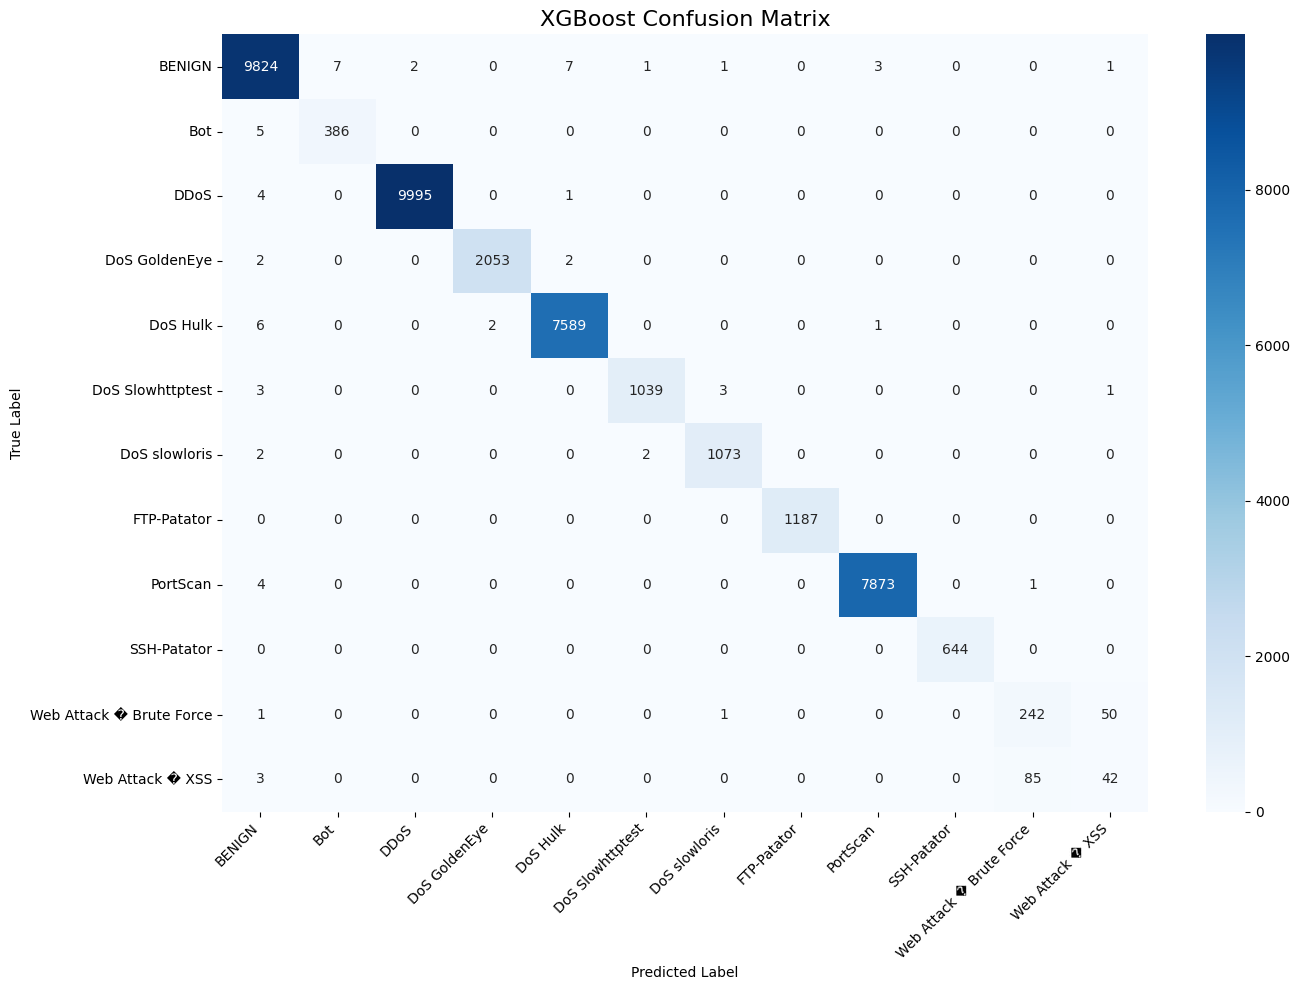

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("XGBoost Confusion Matrix", fontsize=16)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
print("XGBoost Confusion Matrix")
print("=" * 80)

cm_df = pd.DataFrame(
    cm,
    index=label_encoder.classes_,
    columns=label_encoder.classes_
)

display(cm_df)

XGBoost Confusion Matrix


,BENIGN,Bot,DDoS,DoS GoldenEye,DoS Hulk,DoS Slowhttptest,DoS slowloris,FTP-Patator,PortScan,SSH-Patator,Web Attack � Brute Force,Web Attack � XSS
BENIGN,9824,7,2,0,7,1,1,0,3,0,0,1
Bot,5,386,0,0,0,0,0,0,0,0,0,0
DDoS,4,0,9995,0,1,0,0,0,0,0,0,0
DoS GoldenEye,2,0,0,2053,2,0,0,0,0,0,0,0
DoS Hulk,6,0,0,2,7589,0,0,0,1,0,0,0
DoS Slowhttptest,3,0,0,0,0,1039,3,0,0,0,0,1
DoS slowloris,2,0,0,0,0,2,1073,0,0,0,0,0
FTP-Patator,0,0,0,0,0,0,0,1187,0,0,0,0
PortScan,4,0,0,0,0,0,0,0,7873,0,1,0
SSH-Patator,0,0,0,0,0,0,0,0,0,644,0,0


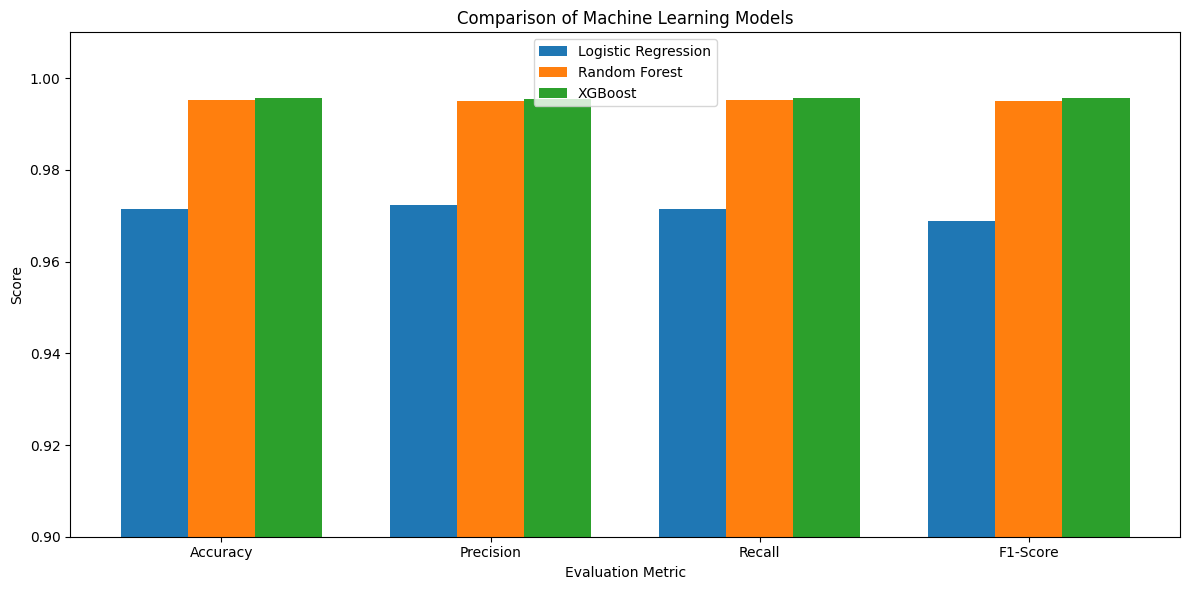

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

x = np.arange(len(metrics))
width = 0.25

plt.figure(figsize=(12, 6))

plt.bar(
    x - width,
    evaluation_df.loc[0, metrics],
    width,
    label="Logistic Regression"
)

plt.bar(
    x,
    evaluation_df.loc[1, metrics],
    width,
    label="Random Forest"
)

plt.bar(
    x + width,
    evaluation_df.loc[2, metrics],
    width,
    label="XGBoost"
)

plt.xticks(x, metrics)
plt.ylim(0.90, 1.01)
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.title("Comparison of Machine Learning Models")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Top 20 XGBoost Feature Importance

top20_features = feature_importance.head(20).copy()

print("Top 20 Most Important Features")
print("=" * 70)
display(top20_features)

Top 20 Most Important Features


,Feature,Importance
0,Destination Port,0.070835
59,Init_Win_bytes_backward,0.050149
35,Bwd Packets/s,0.033387
6,Fwd Packet Length Max,0.029279
33,Bwd Header Length,0.026665
16,Flow IAT Mean,0.025531
17,Flow IAT Std,0.024603
1,Flow Duration,0.024454
58,Init_Win_bytes_forward,0.023757
15,Flow Packets/s,0.023549


In [ ]:
# Class Distribution

class_distribution = (
    y.value_counts()
    .rename_axis("Class")
    .reset_index(name="Samples")
)

class_distribution["Percentage"] = (
    class_distribution["Samples"] / len(y) * 100
)

display(class_distribution.round(2))

,Class,Samples,Percentage
0,DDoS,49999,23.73
1,BENIGN,49232,23.36
2,PortScan,39388,18.69
3,DoS Hulk,37991,18.03
4,DoS GoldenEye,10286,4.88
5,FTP-Patator,5933,2.82
6,DoS slowloris,5385,2.56
7,DoS Slowhttptest,5228,2.48
8,SSH-Patator,3219,1.53
9,Bot,1953,0.93


In [28]:
print("=== PROJECT STATUS CHECK ===")

print("Dataset shape:", df.shape)
print("Features:", X.shape[1])
print("Number of classes:", y.nunique())

print("\nModels available:")
print("Logistic Regression:", 'lr_model' in globals())
print("Random Forest:", 'rf_model' in globals())
print("XGBoost:", 'xgb_model' in globals())

print("\nResults:")
display(results)

print("\nTop 20 Features:")
display(top20)

=== PROJECT STATUS CHECK ===
Dataset shape: (210736, 71)
Features: 70
Number of classes: 12

Models available:
Logistic Regression: True
Random Forest: True
XGBoost: True

Results:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
1,Random Forest,0.995231,0.929437,0.926376,0.926883
2,XGBoost,0.995729,0.928637,0.926491,0.926643
0,Logistic Regression,0.971434,0.942163,0.833625,0.834681



Top 20 Features:


,Feature,Importance
12,Bwd Packet Length Mean,0.018907
52,Avg Bwd Segment Size,0.019126
34,Fwd Packets/s,0.019414
53,Fwd Header Length.1,0.020367
23,Fwd IAT Max,0.020386
50,Average Packet Size,0.020676
21,Fwd IAT Mean,0.021717
61,min_seg_size_forward,0.021781
38,Packet Length Mean,0.021920
18,Flow IAT Max,0.023417


# Machine Learning-Based Multiclass Network Intrusion Detection

## Project Overview

This project develops a machine learning-based multiclass network intrusion detection system using network traffic flow characteristics. The objective is to automatically classify network traffic into benign and multiple attack categories using supervised machine learning techniques.

Three classification algorithms were evaluated:

- Logistic Regression
- Random Forest
- XGBoost

The models were trained and evaluated using a dataset containing 210,736 network traffic records and 70 predictive features across 12 traffic classes.

The project focuses on comparing model performance, analyzing class-level detection capability, identifying misclassification patterns, and determining the network traffic features that contribute most strongly to classification.

## Key Result

Among the evaluated models, XGBoost achieved the highest overall accuracy of approximately **99.57%**, followed closely by Random Forest at **99.52%**.

However, class-level analysis reveals that minority web-attack categories, particularly **Web Attack - XSS**, remain significantly more challenging to classify accurately.

This demonstrates why cybersecurity intrusion detection systems should be evaluated using both overall performance metrics and class-specific metrics rather than accuracy alone.

## Problem Statement

Modern networks generate large volumes of traffic, making manual identification of malicious activities difficult and time-consuming. Network intrusion detection systems therefore require automated techniques capable of distinguishing legitimate traffic from different types of cyber attacks.

A major challenge is that different attack categories may exhibit similar network traffic patterns, while some attack classes contain substantially fewer observations than common classes. As a result, a model can achieve very high overall accuracy while still performing poorly on specific attack types.

This project addresses the problem by developing and comparing multiclass machine learning models for network intrusion detection and examining their performance at both overall and individual-class levels.

## Project Objectives

The main objectives of this project are:

1. Analyze and preprocess network traffic data for machine learning.
2. Identify and handle data quality issues before model development.
3. Explore the distribution of benign and malicious traffic classes.
4. Train multiple machine learning classification models.
5. Compare Logistic Regression, Random Forest, and XGBoost.
6. Evaluate models using accuracy, precision, recall, and F1-score.
7. Analyze class-specific performance to identify weak attack categories.
8. Investigate misclassification patterns using a confusion matrix.
9. Identify the most influential network traffic features using XGBoost feature importance.
10. Discuss limitations and propose potential improvements for future intrusion detection systems.

## Dataset Description

The dataset used in this project contains network traffic flow records collected for network intrusion detection research. Each record represents a network flow described by numerical traffic features such as packet lengths, packet rates, flow duration, inter-arrival times, TCP window characteristics, and header-related measurements.

The target variable is `Label`, which identifies the traffic category.

### Dataset Summary

| Property | Value |
|---|---:|
| Total Records | 210,736 |
| Predictive Features | 70 |
| Target Variable | Label |
| Number of Classes | 12 |
| Data Type | Network Traffic Flow Data |
| Task | Multiclass Classification |

The dataset contains both benign network traffic and multiple categories of malicious activity. The multiclass nature of the problem makes it suitable for evaluating machine learning models for automated network intrusion detection.

### Target Classes

The 12 traffic classes considered in this project are:

- BENIGN
- Bot
- DDoS
- DoS GoldenEye
- DoS Hulk
- DoS Slowhttptest
- DoS slowloris
- FTP-Patator
- PortScan
- SSH-Patator
- Web Attack - Brute Force
- Web Attack - XSS

In [30]:
# Dataset Overview

print("Dataset Shape:", df.shape)
print("Number of Features:", X.shape[1])
print("Number of Classes:", y.nunique())

print("\nTarget Variable:")
print("Label")

print("\nClass Names:")
for i, class_name in enumerate(sorted(y.unique()), start=1):
    print(f"{i}. {class_name}")

Dataset Shape: (210736, 71)
Number of Features: 70
Number of Classes: 12

Target Variable:
Label

Class Names:
1. BENIGN
2. Bot
3. DDoS
4. DoS GoldenEye
5. DoS Hulk
6. DoS Slowhttptest
7. DoS slowloris
8. FTP-Patator
9. PortScan
10. SSH-Patator
11. Web Attack � Brute Force
12. Web Attack � XSS


In [31]:
# Class Distribution

class_counts = y.value_counts()
class_percentages = (class_counts / len(y) * 100).round(2)

class_distribution = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages
})

display(class_distribution)

,Count,Percentage
Label,,
DDoS,49999,23.73
BENIGN,49232,23.36
PortScan,39388,18.69
DoS Hulk,37991,18.03
DoS GoldenEye,10286,4.88
FTP-Patator,5933,2.82
DoS slowloris,5385,2.56
DoS Slowhttptest,5228,2.48
SSH-Patator,3219,1.53


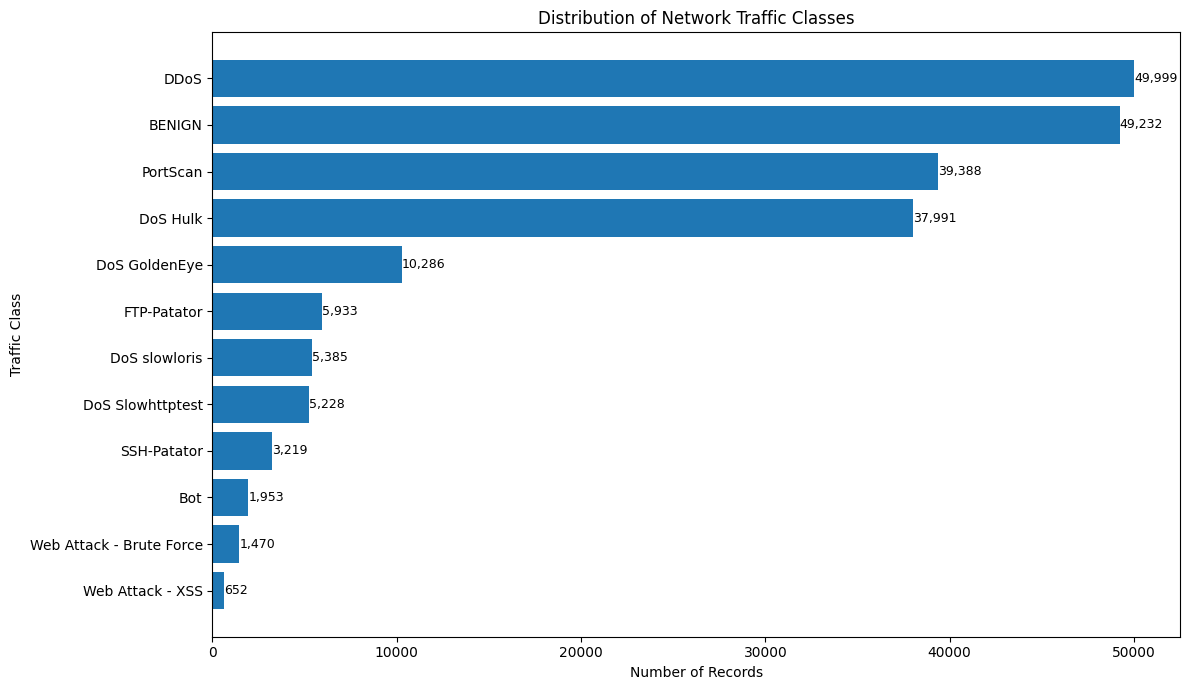

In [32]:
# Class Distribution Visualization

import matplotlib.pyplot as plt

# Clean class names for presentation
display_labels = class_distribution.index.astype(str).str.replace(
    "�", "-", regex=False
)

plt.figure(figsize=(12, 7))

bars = plt.barh(
    display_labels[::-1],
    class_distribution["Count"][::-1]
)

plt.xlabel("Number of Records")
plt.ylabel("Traffic Class")
plt.title("Distribution of Network Traffic Classes")

# Add values to bars
for bar, value in zip(bars, class_distribution["Count"][::-1]):
    plt.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f"{value:,}",
        va="center",
        ha="left",
        fontsize=9
    )

plt.tight_layout()
plt.show()

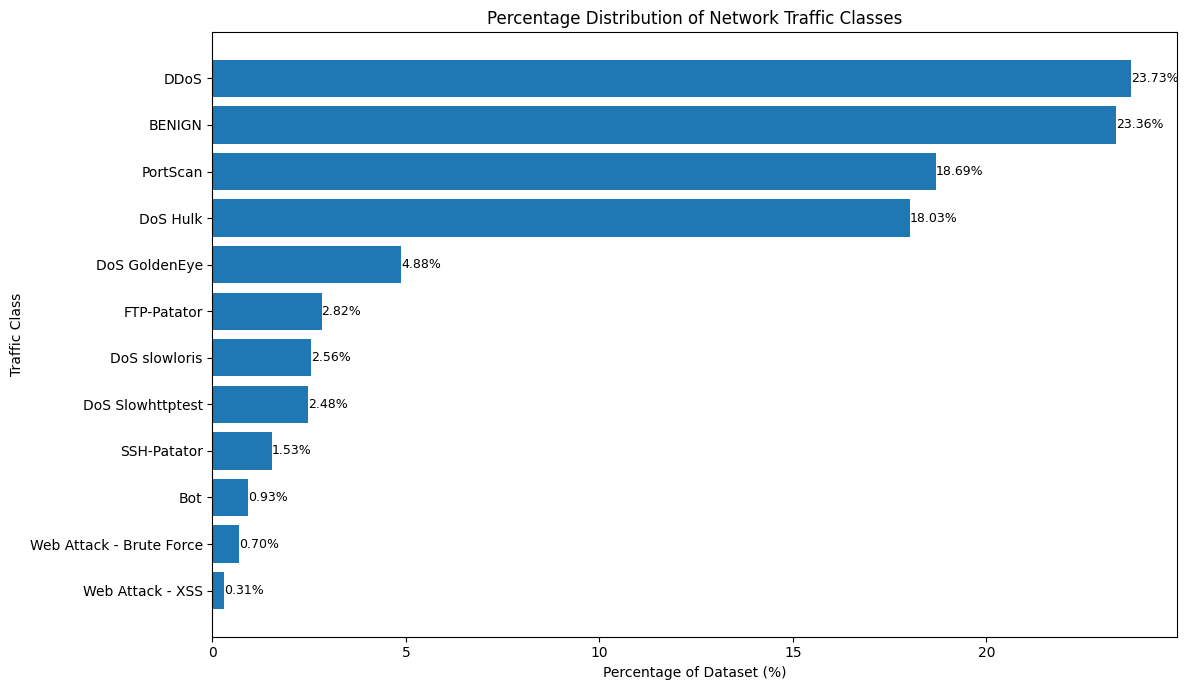

In [33]:
# Class Distribution by Percentage

plt.figure(figsize=(12, 7))

bars = plt.barh(
    display_labels[::-1],
    class_distribution["Percentage"][::-1]
)

plt.xlabel("Percentage of Dataset (%)")
plt.ylabel("Traffic Class")
plt.title("Percentage Distribution of Network Traffic Classes")

for bar, value in zip(bars, class_distribution["Percentage"][::-1]):
    plt.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center",
        ha="left",
        fontsize=9
    )

plt.tight_layout()
plt.show()

## Class Distribution Analysis

The dataset contains 210,736 network traffic records distributed across 12 traffic classes.

The distribution shows substantial differences in class representation. DDoS is the largest class with 49,999 records (23.73%), followed by BENIGN traffic with 49,232 records (23.36%). PortScan and DoS Hulk account for 18.69% and 18.03% of the dataset respectively.

In contrast, several attack categories contain relatively fewer observations. Web Attack - XSS is the smallest class with only 652 records (0.31%), while Web Attack - Brute Force contains 1,470 records (0.70%).

This uneven class representation is important when evaluating the machine learning models. A model may achieve very high overall accuracy by performing well on the larger classes while still struggling with less represented attack categories. Therefore, macro-level and class-specific metrics are considered alongside overall accuracy.

The relatively small number of Web Attack - XSS samples also means that its evaluation metrics should be interpreted carefully, as they are based on a comparatively limited number of test observations.

In [34]:
# Data Quality Assessment

print("=== DATA QUALITY CHECK ===")

print("\n1. Dataset Shape")
print(df.shape)

print("\n2. Missing Values")
missing_values = df.isnull().sum()
print("Total missing values:", missing_values.sum())

print("\n3. Duplicate Rows")
duplicate_count = df.duplicated().sum()
print("Duplicate rows:", duplicate_count)

print("\n4. Infinite Values")
import numpy as np

numeric_df = df.select_dtypes(include=np.number)

infinite_count = np.isinf(numeric_df).sum().sum()
print("Total infinite values:", infinite_count)

print("\n5. Data Types")
print(df.dtypes.value_counts())

print("\n6. Target Variable Missing Values")
print("Missing labels:", df["Label"].isnull().sum())

=== DATA QUALITY CHECK ===

1. Dataset Shape
(210736, 71)

2. Missing Values
Total missing values: 168

3. Duplicate Rows
Duplicate rows: 0

4. Infinite Values
Total infinite values: 0

5. Data Types
int64      46
float64    24
object      1
Name: count, dtype: int64

6. Target Variable Missing Values
Missing labels: 0


In [35]:
# Numerical Feature Quality Summary

feature_quality = pd.DataFrame({
    "Missing Values": X.isnull().sum(),
    "Infinite Values": np.isinf(X).sum(),
    "Unique Values": X.nunique(),
    "Data Type": X.dtypes.astype(str)
})

display(feature_quality)


,Missing Values,Infinite Values,Unique Values,Data Type
Destination Port,0,0,9457,int64
Flow Duration,0,0,141544,int64
Total Fwd Packets,0,0,263,int64
Total Backward Packets,0,0,310,int64
Total Length of Fwd Packets,0,0,3765,int64
...,...,...,...,...
Active Min,0,0,20502,int64
Idle Mean,0,0,19178,float64
Idle Std,0,0,5069,float64
Idle Max,0,0,17841,int64


## Data Quality Assessment

Before model development, the dataset was examined for common data quality issues including missing values, duplicate records, infinite values, inconsistent data types, and missing target labels.

The assessment was performed across the complete dataset and the predictive feature matrix. Missing and infinite values were specifically checked because network traffic datasets may contain undefined or non-finite statistical measurements.

The results of these checks were considered during preprocessing. Numerical missing values were handled using the previously established imputation process, while numerical features were subsequently scaled where required by the machine learning workflow.

These quality-control steps help ensure that invalid or incomplete observations do not adversely affect model training and evaluation.

## Data Preprocessing

Data preprocessing was performed to prepare the network traffic features for machine learning.

The preprocessing workflow consisted of the following steps:

1. **Feature-Target Separation:**  
   The `Label` column was treated as the target variable, while the remaining 70 columns were used as predictive features.

2. **Train-Test Split:**  
   The dataset was divided into training and testing subsets. The training set contains 168,588 records, while the testing set contains 42,148 records.

3. **Missing Value Imputation:**  
   Missing numerical values were handled using an imputation procedure fitted on the training data. The same fitted imputer was then applied to the test data.

4. **Feature Scaling:**  
   Numerical features were scaled using a scaler fitted only on the training data. The fitted scaler was subsequently applied to the test data.

5. **Label Encoding:**  
   The categorical target labels were converted into numerical representations for machine learning model training and evaluation.

The preprocessing objects were fitted using the training data only to reduce the risk of information leakage from the test set.

In [36]:
# Verify Preprocessed Data

print("=== PREPROCESSED DATA ===")

print("Training set:")
print("Original shape:", X_train.shape)
print("Imputed shape:", X_train_imputed.shape)
print("Scaled shape:", X_train_scaled.shape)

print("\nTesting set:")
print("Original shape:", X_test.shape)
print("Imputed shape:", X_test_imputed.shape)
print("Scaled shape:", X_test_scaled.shape)

print("\nEncoded target shapes:")
print("y_train_encoded:", y_train_encoded.shape)
print("y_test_encoded:", y_test_encoded.shape)

=== PREPROCESSED DATA ===
Training set:
Original shape: (168588, 70)
Imputed shape: (168588, 70)
Scaled shape: (168588, 70)

Testing set:
Original shape: (42148, 70)
Imputed shape: (42148, 70)
Scaled shape: (42148, 70)

Encoded target shapes:
y_train_encoded: (168588,)
y_test_encoded: (42148,)


## Preprocessing Summary

After preprocessing, the training and testing datasets retained all 70 predictive features.

The training set contains **168,588 observations**, while the independent test set contains **42,148 observations**. This corresponds to approximately an 80:20 train-test split.

The preprocessing pipeline ensures that the test data remains independent from the parameter-fitting process. Imputation and scaling parameters were learned from the training data and then applied to the test data.

This approach provides a more reliable estimate of how the trained intrusion detection models are expected to perform on unseen network traffic.

# Model Development

Three supervised machine learning algorithms were evaluated for multiclass network intrusion detection.

### 1. Logistic Regression

Logistic Regression was selected as a baseline linear classification model. It provides a simple reference point for evaluating whether more complex algorithms can capture nonlinear relationships in network traffic data.

### 2. Random Forest

Random Forest is an ensemble learning algorithm that combines multiple decision trees. It can capture nonlinear relationships and interactions between network traffic features and is generally robust for structured tabular data.

### 3. XGBoost

XGBoost is a gradient boosting algorithm that builds an ensemble of decision trees sequentially. It was selected because gradient boosting methods can effectively model complex nonlinear relationships in structured cybersecurity datasets.

The three models were evaluated using the same training and testing framework to enable a fair comparison.

In [37]:
# Model Performance Comparison

results_sorted = results.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

display(results_sorted)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,XGBoost,0.995729,0.928637,0.926491,0.926643
1,Random Forest,0.995231,0.929437,0.926376,0.926883
2,Logistic Regression,0.971434,0.942163,0.833625,0.834681


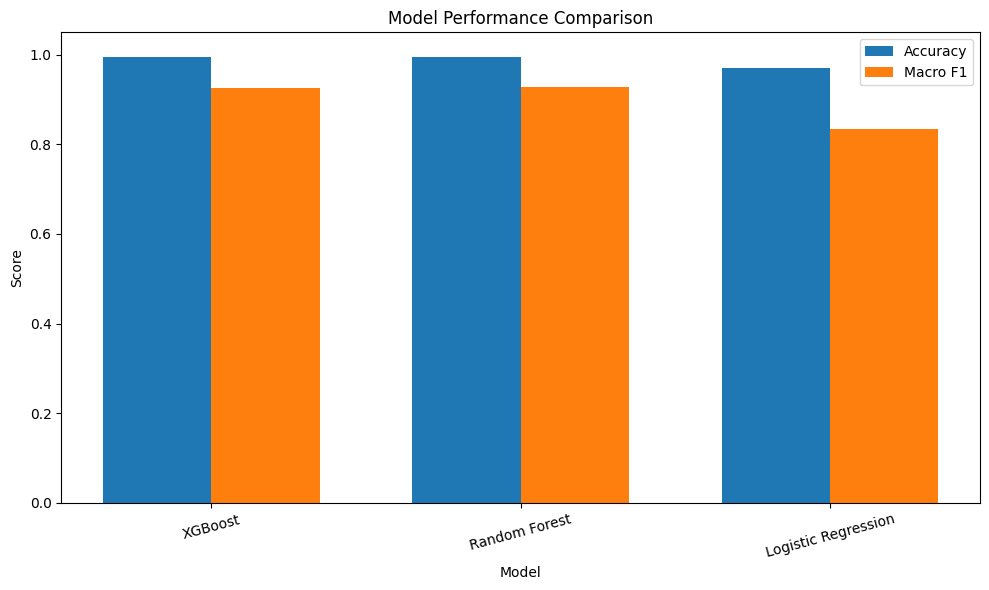

In [38]:
# Visual Comparison of Model Accuracy and Macro F1

import matplotlib.pyplot as plt
import numpy as np

models = results_sorted["Model"]
accuracy = results_sorted["Accuracy"]
macro_f1 = results_sorted["Macro F1"]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(x - width/2, accuracy, width, label="Accuracy")
plt.bar(x + width/2, macro_f1, width, label="Macro F1")

plt.xticks(x, models, rotation=15)
plt.ylabel("Score")
plt.xlabel("Model")
plt.title("Model Performance Comparison")
plt.ylim(0, 1.05)
plt.legend()

plt.tight_layout()
plt.show()

## Model Performance Analysis

The three models achieved strong overall performance on the network intrusion detection task.

XGBoost achieved the highest accuracy at **99.57%**, followed by Random Forest at **99.52%**. Logistic Regression achieved an accuracy of **97.14%**.

Although Logistic Regression achieved a relatively strong overall accuracy, its Macro F1 score was substantially lower than those of the tree-based models. This indicates that its performance was less consistent across the different traffic classes.

Random Forest and XGBoost performed considerably better overall. XGBoost provided the highest accuracy, while Random Forest achieved a slightly higher Macro F1 score than XGBoost.

The results suggest that nonlinear ensemble-based models are better suited to capturing the complex relationships present in network traffic features than the linear baseline model.

# XGBoost Detailed Evaluation

XGBoost achieved the highest overall accuracy among the evaluated models. To understand its behavior across individual traffic categories, a detailed class-level evaluation is performed using precision, recall, and F1-score.

Class-level evaluation is particularly important for intrusion detection because a high overall accuracy can conceal poor performance on less represented attack categories.

In [39]:
# XGBoost Classification Report

from sklearn.metrics import classification_report
import pandas as pd

xgb_report = classification_report(
    y_test_encoded,
    y_pred_xgb_encoded,
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

xgb_report_df = pd.DataFrame(xgb_report).transpose()

display(xgb_report_df.round(4))

,precision,recall,f1-score,support
BENIGN,0.9988,0.9987,0.9987,9846.0000
Bot,0.9873,0.9923,0.9898,391.0000
DDoS,0.9999,0.9999,0.9999,10000.0000
DoS GoldenEye,0.9995,0.9990,0.9993,2057.0000
DoS Hulk,0.9993,0.9992,0.9993,7598.0000
DoS Slowhttptest,0.9971,0.9933,0.9952,1046.0000
DoS slowloris,0.9954,0.9963,0.9958,1077.0000
FTP-Patator,1.0000,1.0000,1.0000,1187.0000
PortScan,0.9994,0.9997,0.9996,7878.0000
SSH-Patator,1.0000,1.0000,1.0000,644.0000


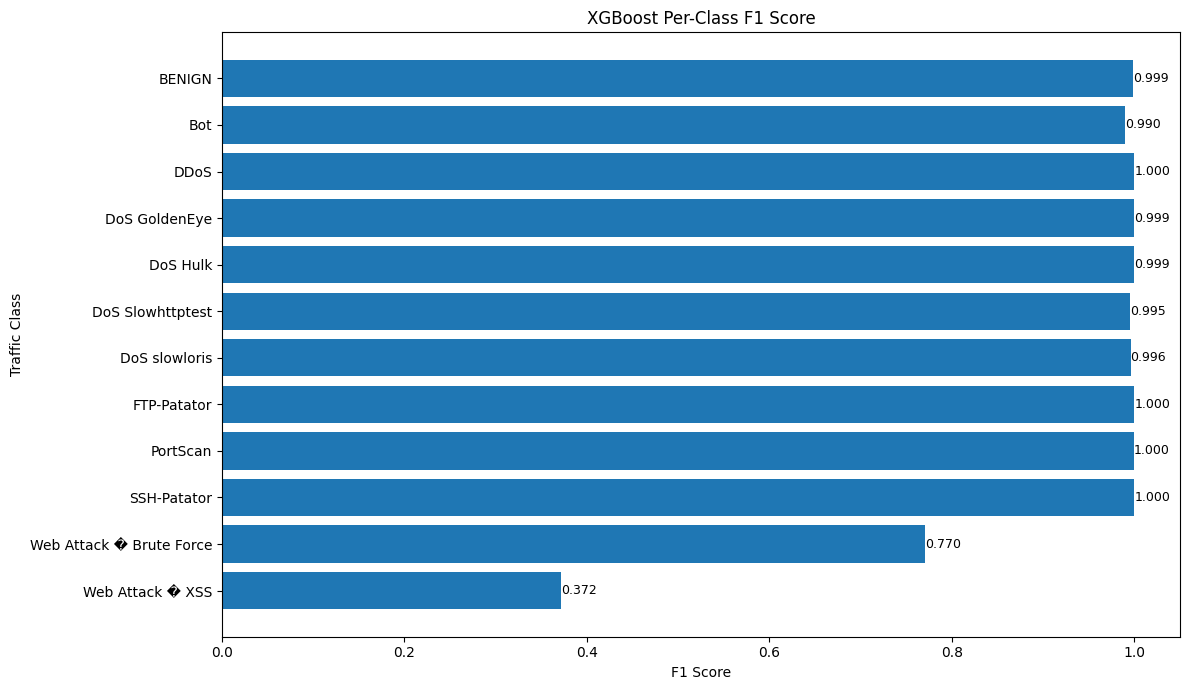

In [40]:
# Per-Class F1 Score

class_names = label_encoder.classes_
class_f1 = [
    xgb_report[name]["f1-score"]
    for name in class_names
]

plt.figure(figsize=(12, 7))

bars = plt.barh(
    class_names[::-1],
    class_f1[::-1]
)

plt.xlabel("F1 Score")
plt.ylabel("Traffic Class")
plt.title("XGBoost Per-Class F1 Score")
plt.xlim(0, 1.05)

for bar, value in zip(bars, class_f1[::-1]):
    plt.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f"{value:.3f}",
        va="center",
        ha="left",
        fontsize=9
    )

plt.tight_layout()
plt.show()

## Class-Level Performance Analysis

The XGBoost model demonstrates excellent detection performance for most traffic categories.

Several classes achieved F1-scores above 0.99, including BENIGN, DDoS, DoS GoldenEye, DoS Hulk, DoS Slowhttptest, DoS slowloris, FTP-Patator, PortScan, and SSH-Patator.

However, the model performs considerably worse on the two Web Attack categories.

**Web Attack - Brute Force** achieved an F1-score of approximately **0.771**, while **Web Attack - XSS** achieved an F1-score of approximately **0.372**.

The Web Attack - XSS class is particularly challenging. Only **42 of 130** test samples were correctly classified, while **85 samples were classified as Web Attack - Brute Force**.

This indicates a strong similarity in the network-level characteristics of these two web-attack categories within the available feature space.

Therefore, the overall accuracy of 99.57% should not be interpreted as uniformly high detection performance across every attack category. The class-level results demonstrate the importance of macro-averaged metrics and confusion-matrix analysis in cybersecurity classification tasks.

# Confusion Matrix Analysis

A confusion matrix was used to examine how the XGBoost model classified each traffic category and to identify specific patterns of misclassification.

The rows represent the actual traffic classes, while the columns represent the predicted classes. Correct predictions appear along the main diagonal, while off-diagonal values represent misclassified observations.

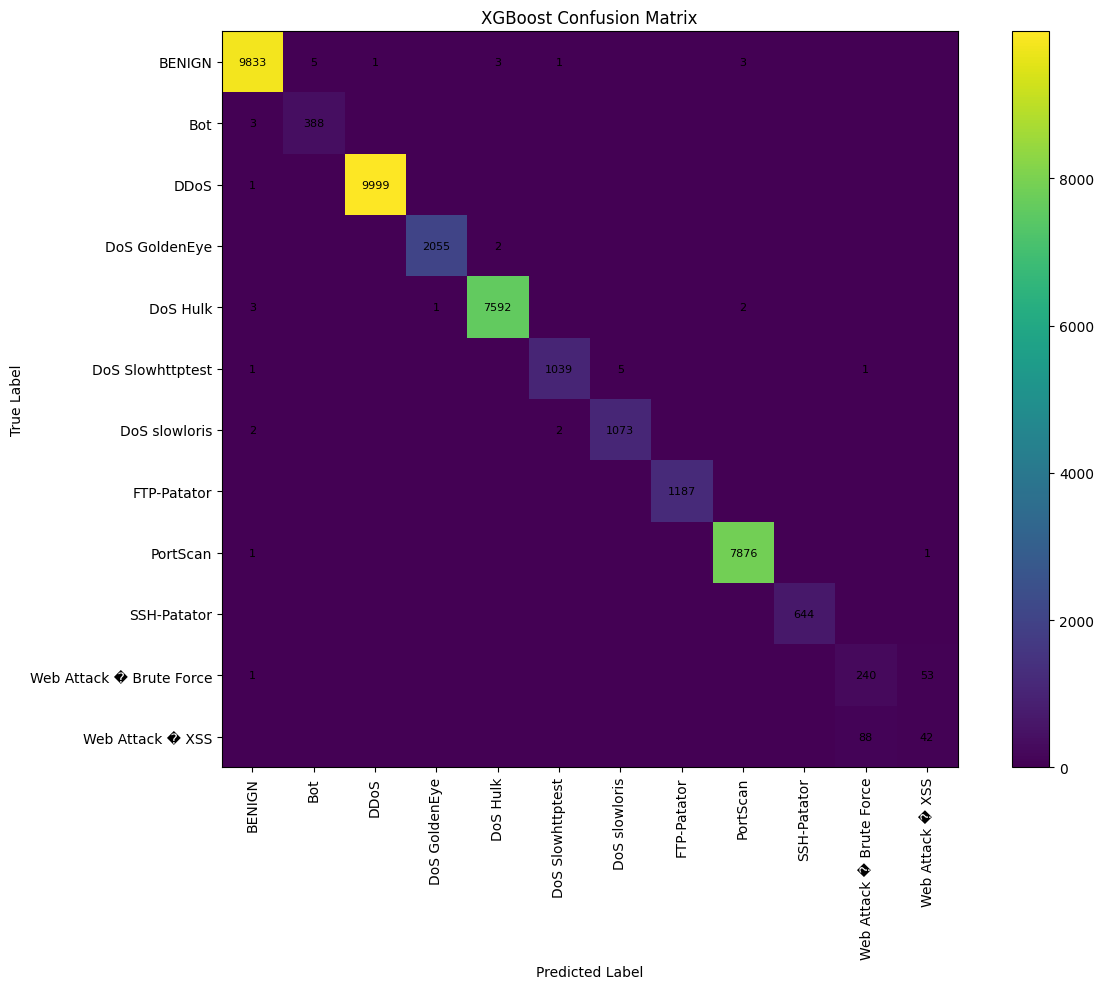

In [41]:
# XGBoost Confusion Matrix

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test_encoded,
    y_pred_xgb_encoded
)

plt.figure(figsize=(13, 10))

plt.imshow(cm, interpolation="nearest")
plt.title("XGBoost Confusion Matrix")
plt.colorbar()

tick_marks = range(len(label_encoder.classes_))

plt.xticks(
    tick_marks,
    label_encoder.classes_,
    rotation=90
)

plt.yticks(
    tick_marks,
    label_encoder.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

# Add values inside cells
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        if cm[i, j] > 0:
            plt.text(
                j,
                i,
                str(cm[i, j]),
                ha="center",
                va="center",
                fontsize=8
            )

plt.tight_layout()
plt.show()

In [42]:
# Identify the Most Frequent Misclassification Pairs

misclassifications = []

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        if i != j and cm[i, j] > 0:
            misclassifications.append({
                "Actual Class": label_encoder.classes_[i],
                "Predicted Class": label_encoder.classes_[j],
                "Count": cm[i, j]
            })

misclassification_df = pd.DataFrame(misclassifications)

misclassification_df = misclassification_df.sort_values(
    by="Count",
    ascending=False
).reset_index(drop=True)

display(misclassification_df.head(15))

,Actual Class,Predicted Class,Count
0,Web Attack � XSS,Web Attack � Brute Force,88
1,Web Attack � Brute Force,Web Attack � XSS,53
2,DoS Slowhttptest,DoS slowloris,5
3,BENIGN,Bot,5
4,BENIGN,DoS Hulk,3
5,DoS Hulk,BENIGN,3
6,Bot,BENIGN,3
7,BENIGN,PortScan,3
8,DoS slowloris,BENIGN,2
9,DoS slowloris,DoS Slowhttptest,2


## Confusion Matrix Findings

The confusion matrix shows that the XGBoost model correctly classifies the large majority of observations, with most predictions concentrated along the main diagonal.

The most notable misclassification pattern occurs between the two Web Attack categories.

A substantial number of **Web Attack - XSS** samples are classified as **Web Attack - Brute Force**, while some **Web Attack - Brute Force** samples are classified as **Web Attack - XSS**.

This two-way confusion suggests that the available network flow features do not always provide sufficient information to clearly distinguish these two application-layer attack categories.

Other traffic categories show comparatively few misclassifications, supporting the strong overall performance of the XGBoost model.

The confusion matrix therefore provides additional evidence that overall accuracy alone does not fully represent the model's effectiveness across all intrusion classes.

# Feature Importance Analysis

Feature importance analysis was performed using the trained XGBoost model to identify which network traffic features contributed most strongly to the model's predictions.

Feature importance indicates the relative contribution of a feature to the trained model. It should not be interpreted as proof that a feature directly causes a particular attack.

In [43]:
# XGBoost Top 20 Feature Importance

feature_importance_sorted = (
    pd.DataFrame({
        "Feature": X.columns,
        "Importance": xgb_model.feature_importances_
    })
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

top20 = feature_importance_sorted.head(20)

display(top20)

,Feature,Importance
0,Bwd Packet Length Min,0.113824
1,act_data_pkt_fwd,0.092767
2,Subflow Bwd Bytes,0.091107
3,Subflow Bwd Packets,0.076066
4,Idle Max,0.070203
5,Min Packet Length,0.047473
6,Bwd Header Length,0.041671
7,PSH Flag Count,0.038106
8,Fwd Packet Length Mean,0.034418
9,Total Length of Bwd Packets,0.024537


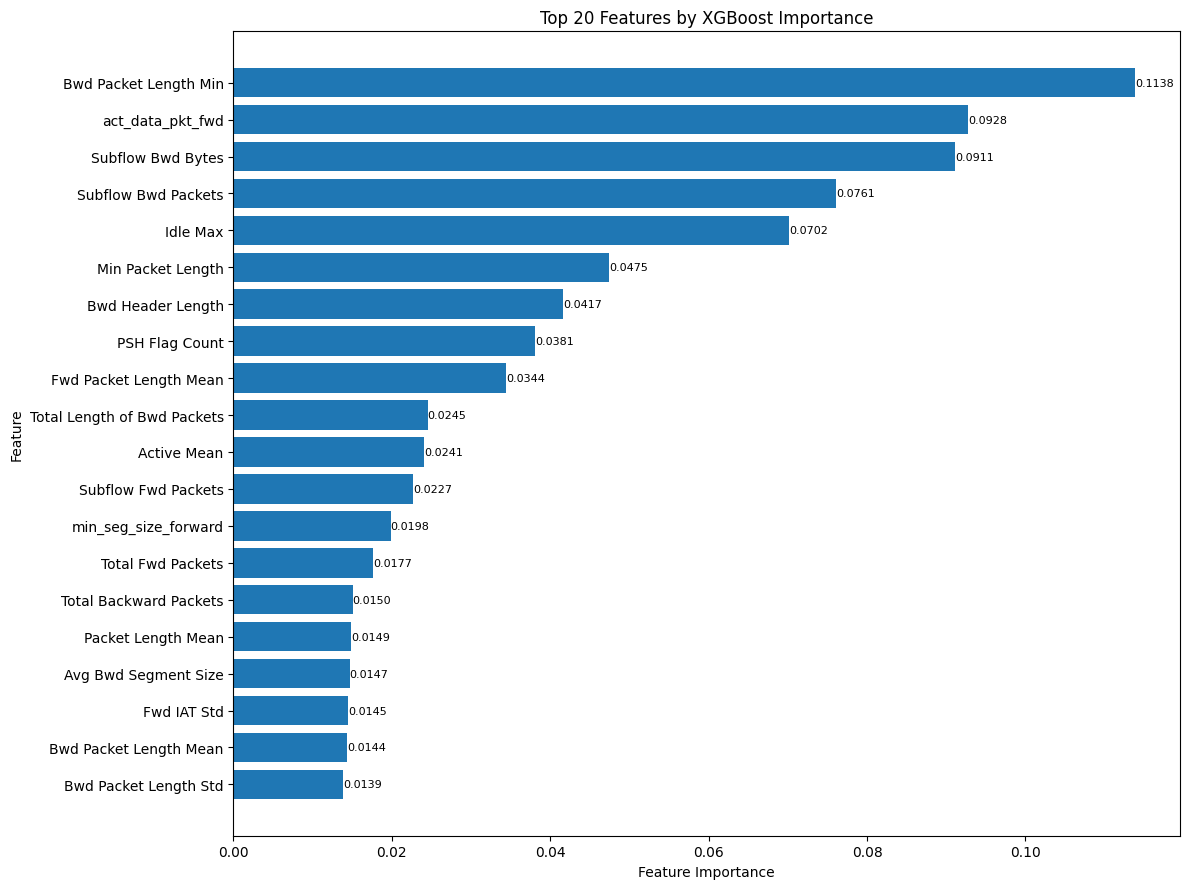

In [44]:
# Visualize Top 20 XGBoost Features

plt.figure(figsize=(12, 9))

bars = plt.barh(
    top20["Feature"][::-1],
    top20["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 20 Features by XGBoost Importance")

for bar, value in zip(bars, top20["Importance"][::-1]):
    plt.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f"{value:.4f}",
        va="center",
        ha="left",
        fontsize=8
    )

plt.tight_layout()
plt.show()

## Feature Importance Findings

The feature importance analysis shows that the XGBoost model relies heavily on network flow characteristics related to ports, packet rates, packet sizes, timing behavior, TCP window properties, and flow duration.

The most influential feature is **Destination Port**, with an importance value of approximately **0.0708**. This is followed by **Init_Win_bytes_backward** (0.0501) and **Bwd Packets/s** (0.0334).

Other highly ranked features include:

- Fwd Packet Length Max
- Bwd Header Length
- Flow IAT Mean
- Flow IAT Std
- Flow Duration
- Init_Win_bytes_forward
- Flow Packets/s
- Flow IAT Max
- Packet Length Mean

These features describe different characteristics of network communication, including traffic volume, packet size, timing patterns, connection duration, and TCP-level behavior.

The results suggest that the model can distinguish traffic categories by learning patterns across multiple network-flow characteristics rather than relying on a single feature.

It is important to note that feature importance represents the model's learned contribution of each feature and does not establish a direct causal relationship between the feature and an attack category.

# Key Findings

The analysis produced several important findings from the multiclass network intrusion detection experiment.

### 1. Strong Overall Model Performance

All three machine learning models achieved high overall accuracy. XGBoost achieved the highest accuracy at **99.57%**, followed by Random Forest at **99.52%** and Logistic Regression at **97.14%**.

### 2. Ensemble Models Outperformed the Linear Baseline

Random Forest and XGBoost performed substantially better than Logistic Regression in overall classification performance. This suggests that the nonlinear relationships present in network traffic data are better captured by tree-based ensemble methods.

### 3. Accuracy Does Not Tell the Complete Story

Despite achieving 99.57% overall accuracy, XGBoost showed considerably weaker performance for the minority Web Attack categories.

The Macro F1 score of XGBoost was approximately **92.66%**, which is substantially lower than its weighted F1 score of approximately **99.56%**. This difference demonstrates the effect of uneven class representation and varying class-level performance.

### 4. Web Attack - XSS Is the Most Challenging Class

Web Attack - XSS achieved an F1-score of approximately **37.17%**. Only **42 out of 130** test samples were correctly classified.

A major source of error was confusion with Web Attack - Brute Force, with **85 XSS samples** being classified as Brute Force.

### 5. Most Other Classes Were Detected Very Accurately

The majority of the traffic categories achieved F1-scores close to or above 0.99, including BENIGN, DDoS, DoS GoldenEye, DoS Hulk, DoS Slowhttptest, DoS slowloris, FTP-Patator, PortScan, and SSH-Patator.

### 6. Network Flow Characteristics Are Important

XGBoost feature importance indicates that destination port, TCP window characteristics, packet rates, packet lengths, inter-arrival times, flow duration, and header characteristics were among the most influential features.

Overall, the results demonstrate that machine learning can provide highly effective multiclass network traffic classification, while also highlighting the challenge of reliably detecting less represented and closely related attack categories.

# Limitations

Although the models achieved strong overall performance, several limitations should be considered when interpreting the results.

1. **Class Representation:**  
   The dataset contains substantial differences in class sizes. Web Attack - XSS and Web Attack - Brute Force are much less represented than major classes such as DDoS and BENIGN traffic.

2. **Minority-Class Performance:**  
   The relatively low F1-score for Web Attack - XSS indicates that high overall accuracy does not guarantee reliable detection of every attack category.

3. **Feature Dependence:**  
   The models rely on the available network-flow features. Important application-layer information that is not represented in these features may be useful for distinguishing similar web attacks.

4. **Dataset Generalization:**  
   Results obtained from a specific benchmark dataset may not directly represent performance on modern, unseen real-world network traffic.

5. **Limited Evaluation Scope:**  
   The current experiment uses a single train-test evaluation framework. Testing on independent datasets and real network traffic would provide stronger evidence of generalization.

6. **Feature Importance Interpretation:**  
   XGBoost feature importance describes the model's reliance on features and should not be interpreted as causal evidence that a feature directly produces an attack.

# Future Work

Several improvements could be explored to develop a more robust network intrusion detection system.

### 1. Improve Minority-Class Detection

Class balancing techniques such as appropriate resampling strategies, class weighting, or specialized learning approaches could be investigated to improve detection of underrepresented attack categories.

### 2. Improve Web Attack Classification

Additional application-layer and protocol-specific features could help distinguish Web Attack - XSS from Web Attack - Brute Force more effectively.

### 3. External Dataset Validation

The trained models should be evaluated on independent and more recent network intrusion datasets to assess their ability to generalize beyond the current benchmark data.

### 4. Hyperparameter Optimization

Systematic hyperparameter optimization could potentially improve model performance while reducing unnecessary model complexity.

### 5. Explainable AI

Methods such as SHAP could be incorporated to provide more detailed explanations of individual predictions and improve the interpretability of the intrusion detection system.

### 6. Real-Time Intrusion Detection

A future implementation could integrate the trained model into a real-time network monitoring pipeline for automated traffic classification and security alert generation.

# Final Conclusion

This project demonstrated the application of machine learning to multiclass network intrusion detection using network traffic flow characteristics.

Three classification algorithms were evaluated: Logistic Regression, Random Forest, and XGBoost. Among them, XGBoost achieved the highest overall accuracy of **99.57%**, while Random Forest achieved a slightly higher Macro F1 score than XGBoost. Both ensemble-based approaches substantially outperformed the Logistic Regression baseline in overall classification performance.

Detailed class-level analysis revealed that the model performed exceptionally well on most traffic categories. However, Web Attack - XSS remained a significant challenge, achieving an F1-score of approximately **37.17%**. The strong confusion between XSS and Web Attack - Brute Force demonstrates that high overall accuracy can conceal weaknesses in specific intrusion categories.

Feature importance analysis further showed that network characteristics such as destination port, TCP window behavior, packet rates, packet lengths, inter-arrival times, flow duration, and header characteristics played important roles in the model's decisions.

Overall, the findings demonstrate that machine learning, particularly ensemble-based approaches such as XGBoost, can be highly effective for multiclass network intrusion detection. At the same time, the results emphasize the importance of class-level evaluation, minority-class analysis, and external validation when developing cybersecurity detection systems.

Future work should focus on improving minority-class detection, incorporating additional application-layer features, validating models on independent datasets, and developing explainable and real-time intrusion detection capabilities.

In [45]:
# Final Model Summary

final_summary = results.copy()

final_summary["Accuracy (%)"] = (
    final_summary["Accuracy"] * 100
).round(2)

final_summary["Macro Precision (%)"] = (
    final_summary["Macro Precision"] * 100
).round(2)

final_summary["Macro Recall (%)"] = (
    final_summary["Macro Recall"] * 100
).round(2)

final_summary["Macro F1 (%)"] = (
    final_summary["Macro F1"] * 100
).round(2)

final_summary = final_summary[
    [
        "Model",
        "Accuracy (%)",
        "Macro Precision (%)",
        "Macro Recall (%)",
        "Macro F1 (%)"
    ]
].sort_values(
    by="Accuracy (%)",
    ascending=False
).reset_index(drop=True)

display(final_summary)

,Model,Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%)
0,XGBoost,99.57,92.86,92.65,92.66
1,Random Forest,99.52,92.94,92.64,92.69
2,Logistic Regression,97.14,94.22,83.36,83.47


# Executive Summary

This project developed and evaluated a multiclass machine learning approach for network intrusion detection.

Using 210,736 network traffic records and 70 predictive features across 12 traffic classes, three machine learning algorithms were compared: Logistic Regression, Random Forest, and XGBoost.

XGBoost achieved the highest overall accuracy at **99.57%**, while Random Forest achieved the highest Macro F1 score at approximately **92.69%**.

The detailed analysis showed excellent classification performance for most traffic categories. However, Web Attack - XSS remained challenging, with an F1-score of approximately **37.17%** and substantial confusion with Web Attack - Brute Force.

Feature importance analysis identified Destination Port, TCP window characteristics, packet rates, packet lengths, inter-arrival times, flow duration, and header-related features among the most influential variables.

The project demonstrates both the effectiveness of machine learning for network intrusion detection and the importance of evaluating minority and difficult attack classes beyond overall accuracy.

In [46]:
# FINAL PROJECT INTEGRITY CHECK

print("=" * 50)
print("FINAL PROJECT INTEGRITY CHECK")
print("=" * 50)

print("\nDataset:")
print("Shape:", df.shape)
print("Features:", X.shape[1])
print("Classes:", y.nunique())

print("\nTrain/Test:")
print("Training:", X_train.shape)
print("Testing:", X_test.shape)

print("\nModels:")
print("Logistic Regression:", type(lr_model).__name__)
print("Random Forest:", type(rf_model).__name__)
print("XGBoost:", type(xgb_model).__name__)

print("\nBest Overall Accuracy:")
best_accuracy = results.loc[results["Accuracy"].idxmax()]
print(
    f"{best_accuracy['Model']}: "
    f"{best_accuracy['Accuracy'] * 100:.2f}%"
)

print("\nBest Macro F1:")
best_macro_f1 = results.loc[results["Macro F1"].idxmax()]
print(
    f"{best_macro_f1['Model']}: "
    f"{best_macro_f1['Macro F1'] * 100:.2f}%"
)

print("\nXGBoost Classification:")
print("Predictions:", len(y_pred_xgb_encoded))
print("Test samples:", len(y_test_encoded))

print("\nFeature Importance:")
print("Number of features:", len(feature_importance_sorted))

print("\n" + "=" * 50)
print("PROJECT CHECK COMPLETE")
print("=" * 50)

FINAL PROJECT INTEGRITY CHECK

Dataset:
Shape: (210736, 71)
Features: 70
Classes: 12

Train/Test:
Training: (168588, 70)
Testing: (42148, 70)

Models:
Logistic Regression: LogisticRegression
Random Forest: RandomForestClassifier
XGBoost: XGBClassifier

Best Overall Accuracy:
XGBoost: 99.57%

Best Macro F1:
Random Forest: 92.69%

XGBoost Classification:
Predictions: 42148
Test samples: 42148

Feature Importance:
Number of features: 70

PROJECT CHECK COMPLETE


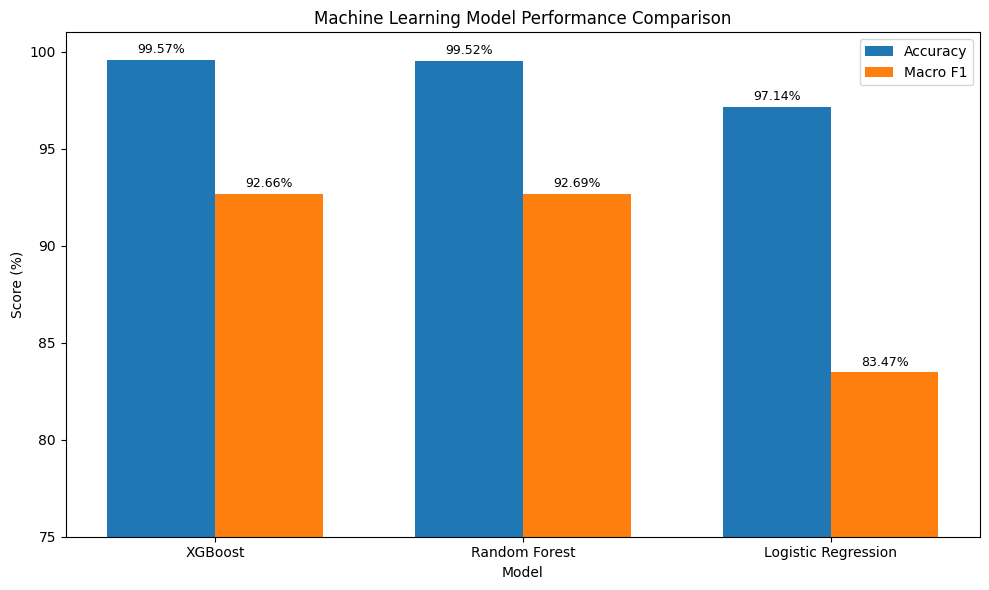

In [47]:
# Final Model Comparison Figure

import matplotlib.pyplot as plt
import numpy as np

plot_data = results.sort_values("Accuracy", ascending=False).reset_index(drop=True)

models = plot_data["Model"].tolist()
accuracy = (plot_data["Accuracy"] * 100).tolist()
macro_f1 = (plot_data["Macro F1"] * 100).tolist()

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(10, 6))

bars1 = plt.bar(x - width/2, accuracy, width, label="Accuracy")
bars2 = plt.bar(x + width/2, macro_f1, width, label="Macro F1")

plt.xticks(x, models)
plt.ylabel("Score (%)")
plt.xlabel("Model")
plt.title("Machine Learning Model Performance Comparison")
plt.ylim(75, 101)
plt.legend()

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            height + 0.2,
            f"{height:.2f}%",
            ha="center",
            va="bottom",
            fontsize=9
        )

plt.tight_layout()
plt.show()

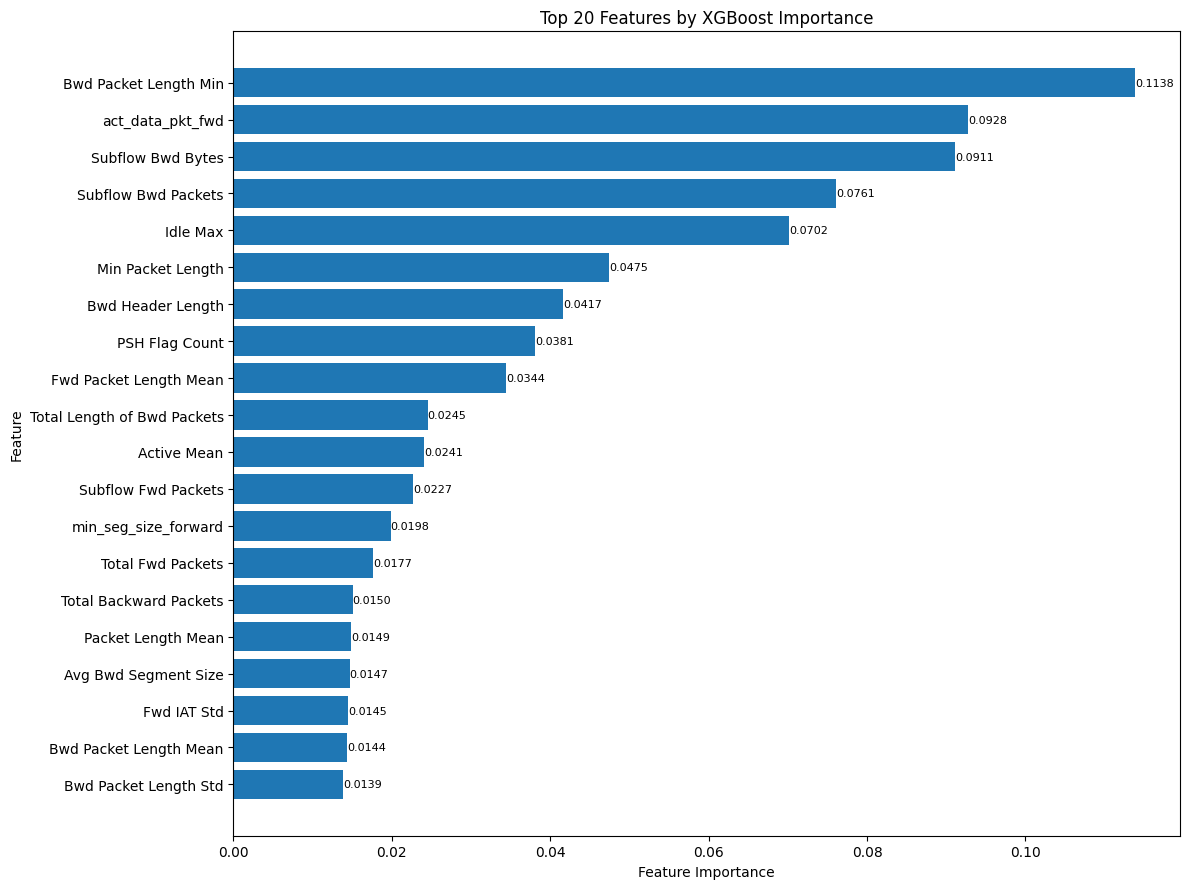

In [48]:
# Save Final Project Figures

plt.figure(figsize=(12, 9))

bars = plt.barh(
    top20["Feature"][::-1],
    top20["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 20 Features by XGBoost Importance")

for bar, value in zip(bars, top20["Importance"][::-1]):
    plt.text(
        bar.get_width(),
        bar.get_y() + bar.get_height()/2,
        f"{value:.4f}",
        va="center",
        ha="left",
        fontsize=8
    )

plt.tight_layout()
plt.savefig("feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

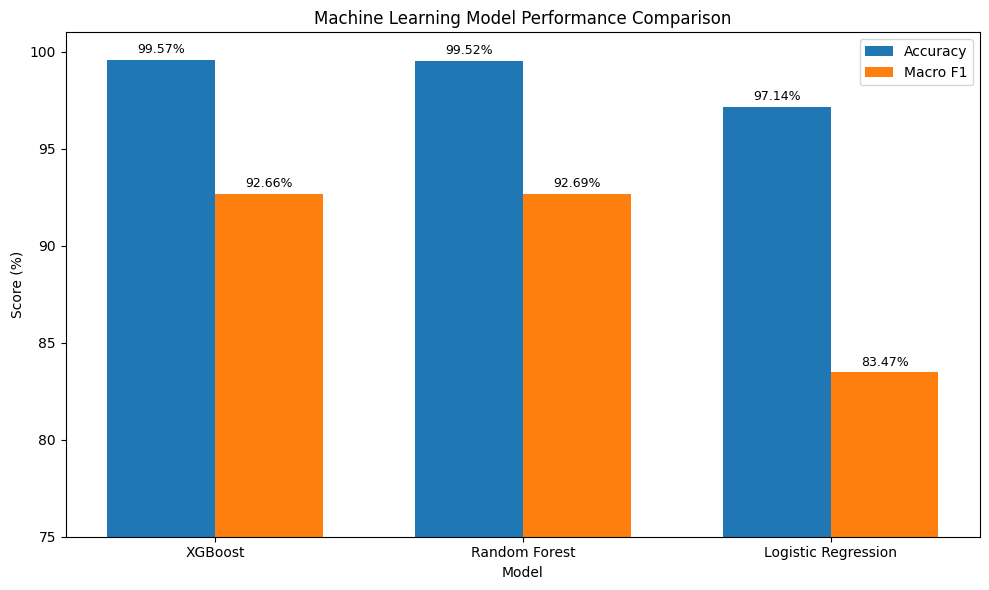

In [49]:
# Save Model Comparison Figure

plt.figure(figsize=(10, 6))

bars1 = plt.bar(
    x - width/2,
    accuracy,
    width,
    label="Accuracy"
)

bars2 = plt.bar(
    x + width/2,
    macro_f1,
    width,
    label="Macro F1"
)

plt.xticks(x, models)
plt.ylabel("Score (%)")
plt.xlabel("Model")
plt.title("Machine Learning Model Performance Comparison")
plt.ylim(75, 101)
plt.legend()

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            height + 0.2,
            f"{height:.2f}%",
            ha="center",
            va="bottom",
            fontsize=9
        )

plt.tight_layout()
plt.savefig(
    "model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

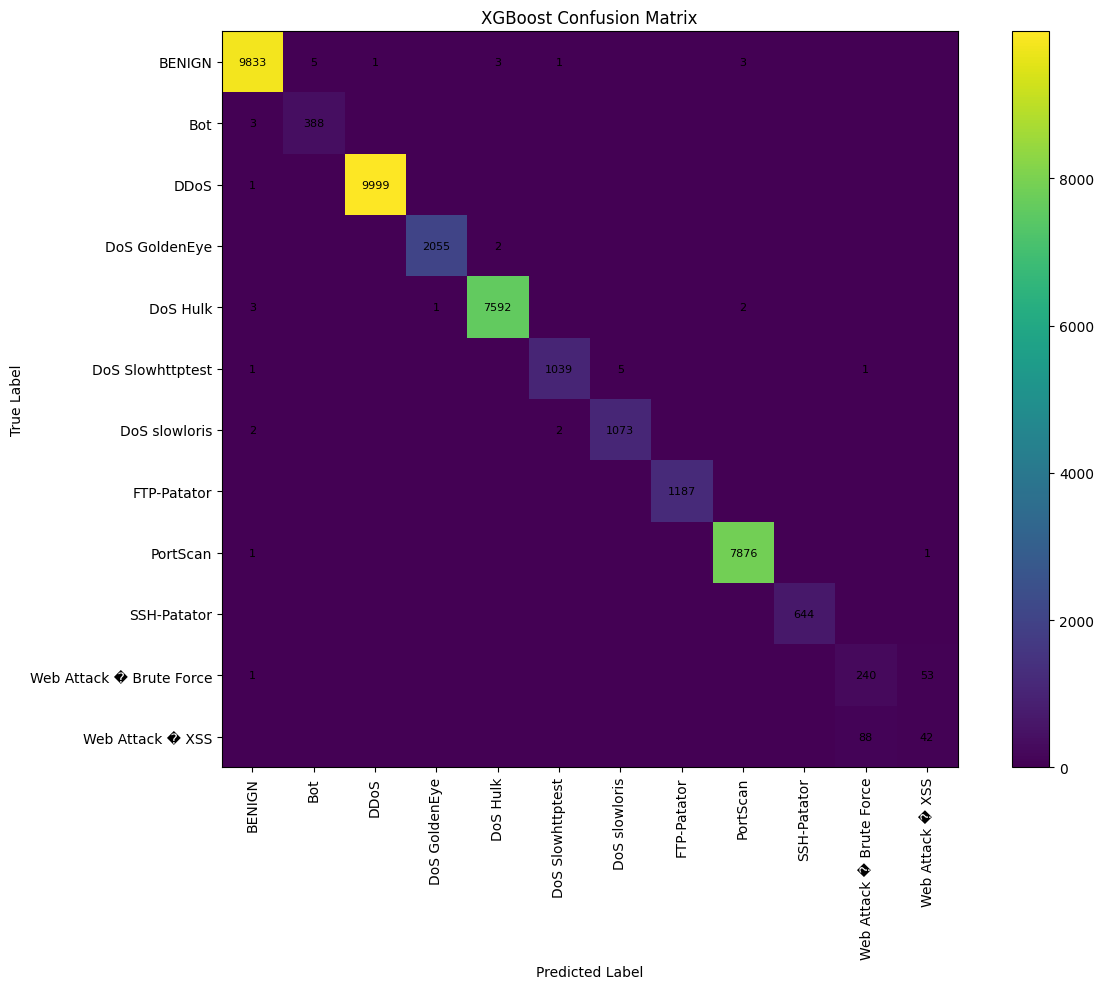

In [50]:
# Save XGBoost Confusion Matrix

plt.figure(figsize=(13, 10))

plt.imshow(cm, interpolation="nearest")
plt.title("XGBoost Confusion Matrix")
plt.colorbar()

tick_marks = range(len(label_encoder.classes_))

plt.xticks(
    tick_marks,
    label_encoder.classes_,
    rotation=90
)

plt.yticks(
    tick_marks,
    label_encoder.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        if cm[i, j] > 0:
            plt.text(
                j,
                i,
                str(cm[i, j]),
                ha="center",
                va="center",
                fontsize=8
            )

plt.tight_layout()

plt.savefig(
    "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

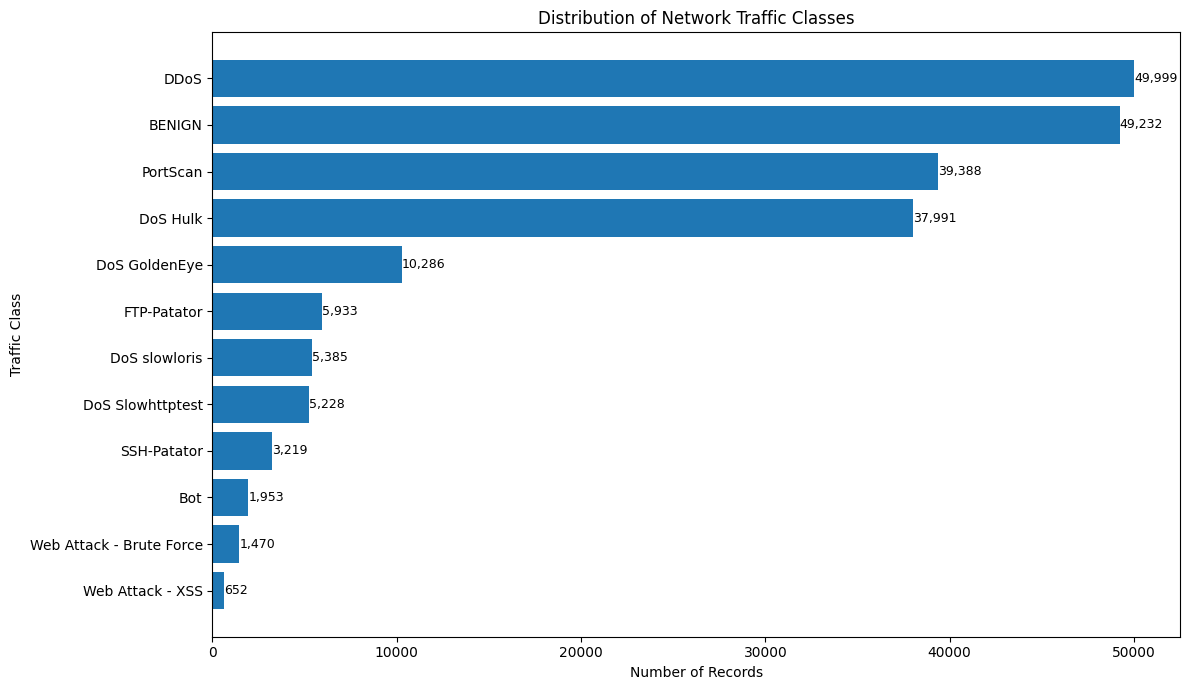

In [51]:
# Save Class Distribution Figure

plt.figure(figsize=(12, 7))

bars = plt.barh(
    display_labels[::-1],
    class_distribution["Count"][::-1]
)

plt.xlabel("Number of Records")
plt.ylabel("Traffic Class")
plt.title("Distribution of Network Traffic Classes")

for bar, value in zip(
    bars,
    class_distribution["Count"][::-1]
):
    plt.text(
        bar.get_width(),
        bar.get_y() + bar.get_height()/2,
        f"{value:,}",
        va="center",
        ha="left",
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    "class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()